In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
os.environ.setdefault("XDG_CACHE_HOME", "/tmp")

import numpy as np
import polars as pl
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

import importlib
from matplotlib_inline.backend_inline import set_matplotlib_formats
import mercury_runs.analysis.study_dataset as sd
import scripts.analysis.load_study_dataset as loader_mod
import mercury_runs.analysis.plotting as plotting

importlib.reload(sd)
importlib.reload(loader_mod)
importlib.reload(plotting)
%matplotlib inline
set_matplotlib_formats("svg")
matplotlib.rcParams["savefig.transparent"] = False
matplotlib.rcParams["figure.facecolor"] = "white"
matplotlib.rcParams["axes.facecolor"] = "white"
plotting.apply_light_mode_plot_style()

In [2]:
REPO_ROOT = Path("/Users/lcarv/PycharmProjects/mercuryv5")
study_root = REPO_ROOT / "results" / "current" / "studies" / "levels_13_21_22_memory_study_fixed_eval_1"

print(study_root)
print(study_root.exists())

dataset = loader_mod.load_mercury_study_dataset(study_root)

/Users/lcarv/PycharmProjects/mercuryv5/results/current/studies/levels_13_21_22_memory_study_fixed_eval_1
True


In [26]:
from mercury_runs.save_results import read_bundle_meta


def _xlogx(x: float) -> float:
    x = float(x)
    return 0.0 if x <= 0.0 else x * np.log(x)


def behaviour_policy_entropy_nats(p_coll: float, epsilon: float, action_count: int) -> float:
    action_count = int(action_count)
    epsilon = float(epsilon)

    p_star = 1.0 - epsilon + epsilon / action_count
    p_other = epsilon / action_count

    h_no_collision = -_xlogx(p_star) - (action_count - 1) * _xlogx(p_other)

    return float(p_coll) * np.log(action_count) + (1.0 - float(p_coll)) * h_no_collision


def repeat_action_probability(p_coll: float, epsilon: float, action_count: int) -> float:
    return (
        float(p_coll) / action_count
        + (1.0 - float(p_coll)) * (1.0 - float(epsilon) + float(epsilon) / action_count)
    )


def _resolve_source_dataset_path(meta, datasets_root=Path("datasets")):
    dataset_name = meta.source.dataset_parquet_name
    if not dataset_name:
        return None

    matches = sorted(datasets_root.rglob(dataset_name))
    return matches[-1] if matches else None


def _action_count(meta, source_dataset_path):
    if source_dataset_path is not None:
        names = pl.scan_parquet(source_dataset_path).collect_schema().names()
    else:
        names = (meta.source_dataset_metadata or {}).get("table", {}).get("columns", [])

    return sum(str(name).startswith("action_") for name in names)


def _collision_rate_hat(meta, source_dataset_path):
    if source_dataset_path is not None:
        collisions = (
            pl.read_parquet(source_dataset_path, columns=["collision"])
            .get_column("collision")
            .to_numpy()
        )
        return float(np.asarray(collisions[:-1], dtype=bool).mean()), "source_parquet"

    source_metadata = meta.source_dataset_metadata or {}
    generation_stats = source_metadata.get("generation_stats", {}) or {}

    saved_steps = int(generation_stats.get("saved_steps") or source_metadata.get("num_steps"))
    if bool(source_metadata.get("valid_trajectories_only")):
        collision_count = 0
    else:
        collision_count = int(generation_stats["dropped_collision_steps"])

    return float(collision_count / max(saved_steps - 1, 1)), "embedded_metadata"


entropy_rows = []

for row in dataset.runs.select(
    "run_id",
    "level",
    "seed",
    "rand_prob",
    "num_steps",
    "mercury_valid_trajectories_only",
    "mercury_split_sensory_raw_latent_valid",
    "mercury_states_parquet",
).iter_rows(named=True):
    meta = read_bundle_meta(Path(row["mercury_states_parquet"]))
    if meta is None:
        raise ValueError(f"No embedded source metadata in {row['mercury_states_parquet']}")

    source_metadata = meta.source_dataset_metadata or {}
    source_dataset_path = _resolve_source_dataset_path(meta)
    action_count = _action_count(meta, source_dataset_path)

    epsilon = float(row["rand_prob"])
    raw_p_coll_hat, entropy_source = _collision_rate_hat(meta, source_dataset_path)

    latent_valid_only = bool(row["mercury_valid_trajectories_only"]) or bool(
        row["mercury_split_sensory_raw_latent_valid"]
    )
    latent_p_coll_hat = 0.0 if latent_valid_only else raw_p_coll_hat

    raw_h_nats = behaviour_policy_entropy_nats(
        p_coll=raw_p_coll_hat,
        epsilon=epsilon,
        action_count=action_count,
    )
    latent_h_nats = behaviour_policy_entropy_nats(
        p_coll=latent_p_coll_hat,
        epsilon=epsilon,
        action_count=action_count,
    )

    entropy_rows.append(
        {
            "run_id": row["run_id"],
            "source_dataset_run_id": source_metadata.get("run_id") or meta.source.dataset_run_id,
            "level": row["level"],
            "seed": row["seed"],
            "epsilon": epsilon,
            "rand_prob": epsilon,
            "num_steps": row["num_steps"],
            "action_count": action_count,
            "mercury_valid_trajectories_only": bool(row["mercury_valid_trajectories_only"]),
            "mercury_split_sensory_raw_latent_valid": bool(row["mercury_split_sensory_raw_latent_valid"]),
            "p_coll_hat": raw_p_coll_hat,
            "rho_bar_hat": (1.0 - epsilon) * (1.0 - raw_p_coll_hat),
            "repeat_action_probability_hat": repeat_action_probability(raw_p_coll_hat, epsilon, action_count),
            "policy_entropy_nats": raw_h_nats,
            "policy_entropy_bits": raw_h_nats / np.log(2.0),
            "latent_p_coll_hat": latent_p_coll_hat,
            "latent_rho_bar_hat": (1.0 - epsilon) * (1.0 - latent_p_coll_hat),
            "latent_repeat_action_probability_hat": repeat_action_probability(
                latent_p_coll_hat,
                epsilon,
                action_count,
            ),
            "latent_policy_entropy_nats": latent_h_nats,
            "latent_policy_entropy_bits": latent_h_nats / np.log(2.0),
            "latent_policy_equivalent_actions": 2**(latent_h_nats / np.log(2.0)),
            "entropy_source": entropy_source,

        }
    )

policy_entropy_by_run = pl.DataFrame(entropy_rows).sort(
    ["level", "rand_prob", "mercury_split_sensory_raw_latent_valid", "seed"]
)

policy_entropy_by_regime = (
    policy_entropy_by_run
    .unique(
        subset=[
            "source_dataset_run_id",
            "mercury_valid_trajectories_only",
            "mercury_split_sensory_raw_latent_valid",
        ],
        keep="first",
    )
    .group_by(["level", "rand_prob", "mercury_split_sensory_raw_latent_valid"])
    .agg(
        pl.len().alias("n_trajectories"),
        pl.col("action_count").first().alias("action_count"),
        pl.col("p_coll_hat").mean().alias("p_coll_hat_mean"),
        pl.col("p_coll_hat").std().fill_null(0.0).alias("p_coll_hat_std"),
        pl.col("rho_bar_hat").mean().alias("rho_bar_hat_mean"),
        pl.col("repeat_action_probability_hat").mean().alias("repeat_action_probability_hat_mean"),
        pl.col("policy_entropy_nats").mean().alias("policy_entropy_nats_mean"),
        pl.col("policy_entropy_nats").std().fill_null(0.0).alias("policy_entropy_nats_std"),
        pl.col("policy_entropy_bits").mean().alias("policy_entropy_bits_mean"),
        pl.col("policy_entropy_bits").std().fill_null(0.0).alias("policy_entropy_bits_std"),
        pl.col("latent_p_coll_hat").mean().alias("latent_p_coll_hat_mean"),
        pl.col("latent_p_coll_hat").std().fill_null(0.0).alias("latent_p_coll_hat_std"),
        pl.col("latent_rho_bar_hat").mean().alias("latent_rho_bar_hat_mean"),
        pl.col("latent_repeat_action_probability_hat").mean().alias("latent_repeat_action_probability_hat_mean"),
        pl.col("latent_policy_entropy_nats").mean().alias("latent_policy_entropy_nats_mean"),
        pl.col("latent_policy_entropy_nats").std().fill_null(0.0).alias("latent_policy_entropy_nats_std"),
        pl.col("latent_policy_entropy_bits").mean().alias("latent_policy_entropy_bits_mean"),
        pl.col("latent_policy_entropy_bits").std().fill_null(0.0).alias("latent_policy_entropy_bits_std"),
        pl.col("latent_policy_equivalent_actions").mean().fill_null(0.0).alias
        ("latent_policy_equivalent_actions"),
        pl.col("latent_policy_equivalent_actions").std().fill_null(0.0).alias
        ("latent_policy_equivalent_actions_std"),
        pl.col("entropy_source").unique().alias("entropy_sources"),
    )
    .sort(["level", "rand_prob", "mercury_split_sensory_raw_latent_valid"])
)

policy_entropy_by_regime


level,rand_prob,mercury_split_sensory_raw_latent_valid,n_trajectories,action_count,p_coll_hat_mean,p_coll_hat_std,rho_bar_hat_mean,repeat_action_probability_hat_mean,policy_entropy_nats_mean,policy_entropy_nats_std,policy_entropy_bits_mean,policy_entropy_bits_std,latent_p_coll_hat_mean,latent_p_coll_hat_std,latent_rho_bar_hat_mean,latent_repeat_action_probability_hat_mean,latent_policy_entropy_nats_mean,latent_policy_entropy_nats_std,latent_policy_entropy_bits_mean,latent_policy_entropy_bits_std,latent_policy_equivalent_actions,latent_policy_equivalent_actions_std,entropy_sources
i64,f64,bool,u32,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,list[str]
13,0.0,false,10,4,0.5012,0.001655,0.4988,0.6241,0.694811,0.002295,1.0024,0.003311,0.5012,0.001655,0.4988,0.6241,0.694811,0.002295,1.0024,0.003311,2.003335,0.0046,"[""embedded_metadata""]"
13,0.0,true,10,4,0.5012,0.001655,0.4988,0.6241,0.694811,0.002295,1.0024,0.003311,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,"[""embedded_metadata""]"
13,0.3,false,10,4,0.499895,0.002793,0.350074,0.512555,1.083259,0.001692,1.562813,0.002441,0.499895,0.002793,0.350074,0.512555,1.083259,0.001692,1.562813,0.002441,2.954297,0.005003,"[""embedded_metadata""]"
13,0.3,true,10,4,0.499895,0.002793,0.350074,0.512555,1.083259,0.001692,1.562813,0.002441,0.0,0.0,0.7,0.775,0.780352,0.0,1.125809,0.0,2.182239,0.0,"[""embedded_metadata""]"
20,0.0,false,10,4,0.50081,0.003619,0.49919,0.624392,0.69427,0.005017,1.00162,0.007238,0.50081,0.003619,0.49919,0.624392,0.69427,0.005017,1.00162,0.007238,2.00227,0.010052,"[""embedded_metadata""]"
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
20,0.3,true,10,4,0.534267,0.004518,0.326013,0.49451,1.104087,0.002738,1.59286,0.00395,0.0,0.0,0.7,0.775,0.780352,0.0,1.125809,0.0,2.182239,0.0,"[""embedded_metadata""]"
21,0.0,false,10,4,0.572359,0.004062,0.427641,0.570731,0.793458,0.005632,1.144717,0.008125,0.572359,0.004062,0.427641,0.570731,0.793458,0.005632,1.144717,0.008125,2.211059,0.012448,"[""embedded_metadata""]"
21,0.0,true,10,4,0.572359,0.004062,0.427641,0.570731,0.793458,0.005632,1.144717,0.008125,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,"[""embedded_metadata""]"


In [3]:
print(sd.__file__)
print(dataset.runs.columns)
print(dataset.history.shape)
print(dataset.states.shape)
print(dataset.history.columns)

/Users/lcarv/PycharmProjects/mercuryv5/src/mercury_runs/analysis/study_dataset.py
['run_id', 'timestamp_utc', 'method', 'level', 'sensor', 'sensor_range', 'seed', 'rand_prob', 'num_steps', 'window_length', 'memory_length', 'activation_threshold', 'sensory_weighting', 'ambiguity_threshold', 'ambiguity_decay', 'trace_decay', 'lambda_trace', 'weight_memory', 'weight_undirected', 'weight_base', 'weight_action', 'memory_replay', 'memory_disambiguation', 'am_n_codebook', 'am_lr', 'am_sigma', 'am_key', 'run_status', 'run_root', 'study', '_worker_run', 'max_workers', 'no_parallel', 'resume', 'continue_on_error', 'retry_failed', 'retry_incomplete', 'wandb', 'wandb_project', 'wandb_mode', 'wandb_job_type', 'wandb_log_artifacts', 'baseline_pocml', 'baseline_all', 'pocml_epochs', 'pocml_trajectory_length', 'pocml_state_dim', 'pocml_random_feature_dim', 'pocml_alpha', 'pocml_lr_q', 'pocml_lr_v', 'pocml_lr_all', 'pocml_lr_m', 'pocml_reg_m', 'pocml_max_iter_m', 'pocml_eps_m', 'pocml_batch_size', 'poc

In [4]:
results = dataset.history_with_run_metadata(["level", "rand_prob",
                                             "weight_memory", "mercury_split_sensory_raw_latent_valid"])
print(results.shape)


(5040, 39)


In [5]:
def state_recall_from_cooccurrence(matrix):
    if matrix is None:
        return None
    if hasattr(matrix, "to_list"):
        matrix = matrix.to_list()
    C = np.asarray(matrix, dtype=np.float64)
    if C.ndim != 2 or C.size == 0:
        return None
    total = C.sum()
    if total <= 0:
        return None
    return float(C.max(axis=0).sum() / total)


history_with_state_recall = dataset.history.with_columns(
    pl.col("sensory_exact_state_cooccurrence_matrix")
    .map_elements(state_recall_from_cooccurrence, return_dtype=pl.Float64)
    .alias("sensory_state_recall"),
    pl.col("latent_exact_state_cooccurrence_matrix")
    .map_elements(state_recall_from_cooccurrence, return_dtype=pl.Float64)
    .alias("latent_state_recall"),
)

results = history_with_state_recall.join(
    dataset.run_metadata([
        "level",
        "rand_prob",
        "weight_memory",
        "mercury_split_sensory_raw_latent_valid",
    ]),
    on="run_id",
    how="left",
    coalesce=True,
)

print(results.select("sensory_state_recall", "latent_state_recall").drop_nulls().head())


shape: (5, 2)
┌──────────────────────┬─────────────────────┐
│ sensory_state_recall ┆ latent_state_recall │
│ ---                  ┆ ---                 │
│ f64                  ┆ f64                 │
╞══════════════════════╪═════════════════════╡
│ 1.0                  ┆ 1.0                 │
│ 1.0                  ┆ 0.70626             │
│ 1.0                  ┆ 0.716275            │
│ 1.0                  ┆ 0.58903             │
│ 1.0                  ┆ 0.45522             │
└──────────────────────┴─────────────────────┘


f490e5066841
(21, 3)
[   1 1000 2000 3000 4000] [0.820785 0.89135  0.891345 0.889465 0.86479 ]
d05e5e6c622f
(21, 3)
[   1 1000 2000 3000 4000] [0.82086  0.885475 0.88894  0.82208  0.82086 ]
100b72c07049
(21, 3)
[   1 1000 2000 3000 4000] [0.8208   0.88561  0.885385 0.88936  0.890785]
4e68b0806ea4
(21, 3)
[   1 1000 2000 3000 4000] [0.821355 0.933435 0.926485 0.924185 0.92234 ]
c33e57820942
(21, 3)
[   1 1000 2000 3000 4000] [0.821525 0.932315 0.93196  0.93217  0.929355]
e22996399995
(21, 3)
[   1 1000 2000 3000 4000] [0.82142  0.93281  0.855855 0.892605 0.927715]
973f302690f4
(21, 3)
[   1 1000 2000 3000 4000] [0.82162  0.932065 0.93236  0.830325 0.91687 ]
b79ff24166c5
(21, 3)
[   1 1000 2000 3000 4000] [0.821335 0.935445 0.93126  0.932205 0.93424 ]
65fd59d1518f
(21, 3)
[   1 1000 2000 3000 4000] [0.820885 0.885385 0.89058  0.890865 0.889355]
d1172a933bd1
(21, 3)
[   1 1000 2000 3000 4000] [0.820575 0.932755 0.93404  0.931705 0.93246 ]


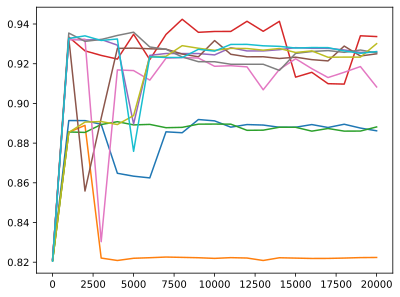

In [6]:

level_20_latent_precision =(
    results
    .filter(pl.col("level") == 21,
            pl.col("rand_prob") == 0.3,
            pl.col("weight_memory") == 0.8,
            pl.col("mercury_split_sensory_raw_latent_valid") == False,
            )
    .select(
        pl.col("run_id"),
        pl.col("step"),
        pl.col("latent_precision")
    )
)

runs = level_20_latent_precision.unique("run_id").select("run_id").to_series().to_list()

for run in runs:
    print(run)
    level_20_latent_precision_filtered = level_20_latent_precision.filter(pl.col("run_id") == run)


    x_values = level_20_latent_precision_filtered["step"].to_numpy()
    y_values = (level_20_latent_precision_filtered["latent_precision"]
                .to_numpy())
    print(level_20_latent_precision_filtered.shape)
    print(x_values[:5], y_values[:5])
    plt.plot(x_values, y_values)

plt.show()

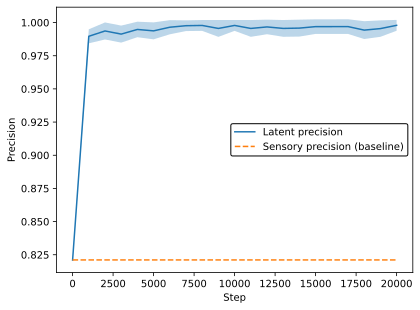

In [7]:

filtered = (
    results
    .filter(
        pl.col("level") == 21,
        pl.col("rand_prob") == 0.3,
        pl.col("weight_memory") == 0.8,
        pl.col("mercury_split_sensory_raw_latent_valid") == True,
    )
    .select(
        "run_id",
        "step",
        "latent_precision",
        "sensory_precision",  # <-- include this
    )
)

# Aggregate
summary = (
    filtered
    .group_by("step")
    .agg(
        pl.col("latent_precision").mean().alias("latent_mean"),
        pl.col("latent_precision").std().alias("latent_std"),

        pl.col("sensory_precision").mean().alias("sensory_mean"),
        pl.col("sensory_precision").std().alias("sensory_std"),
    )
    .sort("step")
)

x = summary["step"].to_numpy()

latent_mean = summary["latent_mean"].to_numpy()
latent_std = summary["latent_std"].fill_null(0).to_numpy()

sensory_mean = summary["sensory_mean"].to_numpy()
sensory_std = summary["sensory_std"].fill_null(0).to_numpy()

# Plot latent (mean + shaded std)
plt.plot(x, latent_mean, label="Latent precision")
plt.fill_between(
    x,
    latent_mean - latent_std,
    latent_mean + latent_std,
    alpha=0.3,
)

# Plot sensory baseline
plt.plot(
    x,
    sensory_mean,
    linestyle="--",
    label="Sensory precision (baseline)"
)

# Optional: add shading for sensory as well
# plt.fill_between(
#     x,
#     sensory_mean - sensory_std,
#     sensory_mean + sensory_std,
#     alpha=0.15,
# )

plt.xlabel("Step")
plt.ylabel("Precision")
plt.legend()
plt.show()

Saved plot: results/current/notebook_plots/latent_transition_precision_w_mem_1_0_collision_conditioned_true.png


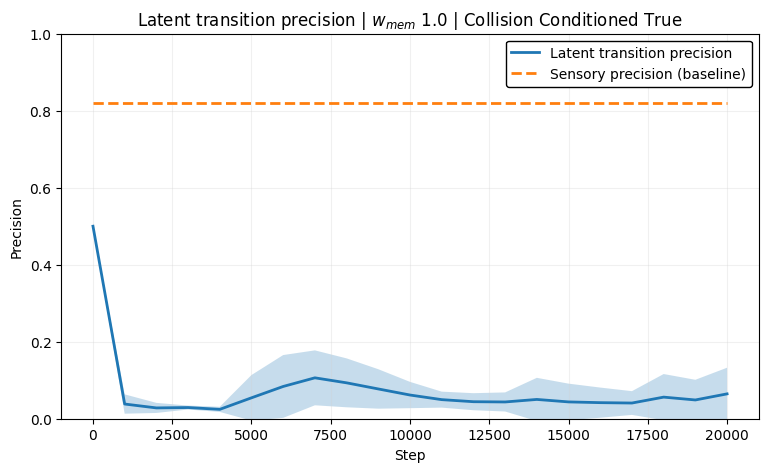

SummaryFrameBundle(raw_frames_by_series_name={'latent_precision_main': shape: (210, 3)
┌──────────────┬───────┬─────────────────────────────┐
│ run_id       ┆ step  ┆ latent_mean_total_variation │
│ ---          ┆ ---   ┆ ---                         │
│ str          ┆ i64   ┆ f64                         │
╞══════════════╪═══════╪═════════════════════════════╡
│ 06997ca9fc3e ┆ 1     ┆ 0.5                         │
│ 06997ca9fc3e ┆ 1000  ┆ 0.050885                    │
│ 06997ca9fc3e ┆ 2000  ┆ 0.042785                    │
│ 06997ca9fc3e ┆ 3000  ┆ 0.027882                    │
│ 06997ca9fc3e ┆ 4000  ┆ 0.036858                    │
│ …            ┆ …     ┆ …                           │
│ b185252b2108 ┆ 16000 ┆ 0.030197                    │
│ b185252b2108 ┆ 17000 ┆ 0.029614                    │
│ b185252b2108 ┆ 18000 ┆ 0.029273                    │
│ b185252b2108 ┆ 19000 ┆ 0.026303                    │
│ b185252b2108 ┆ 20000 ┆ 0.029146                    │
└──────────────┴───────┴─────────

In [8]:
comparison_plot_base = plotting.NotebookPlot(
    shared_filters={
        "level": 21,
        "rand_prob": 0.3,
    },
    series=[
        plotting.NotebookSeries(
            name="latent_precision_main",
            metric_column_name="latent_mean_total_variation",
            label="Latent transition precision",
            filter_values={
                "weight_memory": 1.0,
                "mercury_split_sensory_raw_latent_valid": True,
            },
            band_alpha=0.25,
        ),
        plotting.NotebookSeries(
            name="sensory_precision_baseline",
            metric_column_name="sensory_precision",
            label="Sensory precision",
            filter_values={
                "weight_memory": 0.8,
                "mercury_split_sensory_raw_latent_valid": False,
            },
            line_style="--",
            show_standard_deviation_band=False,
            is_baseline=True,
        ),
    ],
    y_axis_label="Precision",
    y_limits=(0.0, 1.0),
    use_grid=True,
)

comparison_plot = plotting.NotebookPlot(
    shared_filters=comparison_plot_base.shared_filters,
    series=comparison_plot_base.series,
    title_spec=plotting.prefilled_title_spec_from_canonical_parameters(
        comparison_plot_base,
        plotting.CANONICAL_TITLE_PARAMETERS,
        parameter_order=plotting.CANONICAL_TITLE_PARAMETER_ORDER,
        default_source_series_name="latent_precision_main",
        metric_label_mode="first_series",
    ),
    y_axis_label=comparison_plot_base.y_axis_label,
    y_limits=comparison_plot_base.y_limits,
    use_grid=comparison_plot_base.use_grid,
)

plotting.display_notebook_plot(results, comparison_plot)

In [9]:
def with_auto_title(plot_base, metric_label_mode="first_series", default_source_series_name=None):
    return plotting.NotebookPlot(
        shared_filters=plot_base.shared_filters,
        series=plot_base.series,
        title_spec=plotting.prefilled_title_spec_from_canonical_parameters(
            plot_base,
            plotting.CANONICAL_TITLE_PARAMETERS,
            parameter_order=plotting.CANONICAL_TITLE_PARAMETER_ORDER,
            default_source_series_name=default_source_series_name,
            metric_label_mode=metric_label_mode,
        ),
        figure_size=plot_base.figure_size,
        x_column_name=plot_base.x_column_name,
        run_column_name=plot_base.run_column_name,
        x_axis_label=plot_base.x_axis_label,
        y_axis_label=plot_base.y_axis_label,
        y_limits=plot_base.y_limits,
        x_limits=plot_base.x_limits,
        show_legend=plot_base.show_legend,
        legend_location=plot_base.legend_location,
        use_grid=plot_base.use_grid,
        aggregation_mode=plot_base.aggregation_mode,
        mean_alias_suffix=plot_base.mean_alias_suffix,
        std_alias_suffix=plot_base.std_alias_suffix,
        fill_null_standard_deviation_with=plot_base.fill_null_standard_deviation_with,
        smoothing_mode=plot_base.smoothing_mode,
        smoothing_window_size=plot_base.smoothing_window_size,
        smoothing_min_periods=plot_base.smoothing_min_periods,
        output_path=plot_base.output_path,
    )

Saved plot: results/current/notebook_plots/latent_precision_w_mem_0_8.png


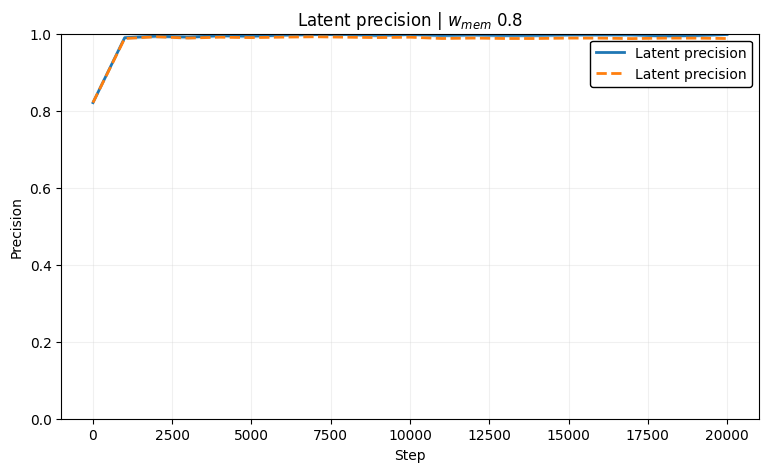

SummaryFrameBundle(raw_frames_by_series_name={'memory_08': shape: (210, 3)
┌──────────────┬───────┬──────────────────┐
│ run_id       ┆ step  ┆ latent_precision │
│ ---          ┆ ---   ┆ ---              │
│ str          ┆ i64   ┆ f64              │
╞══════════════╪═══════╪══════════════════╡
│ 2e41f4dfe26b ┆ 1     ┆ 0.821205         │
│ 2e41f4dfe26b ┆ 1000  ┆ 0.98627          │
│ 2e41f4dfe26b ┆ 2000  ┆ 0.986275         │
│ 2e41f4dfe26b ┆ 3000  ┆ 0.986275         │
│ 2e41f4dfe26b ┆ 4000  ┆ 0.997655         │
│ …            ┆ …     ┆ …                │
│ f412e14eb9c2 ┆ 16000 ┆ 0.986525         │
│ f412e14eb9c2 ┆ 17000 ┆ 0.98656          │
│ f412e14eb9c2 ┆ 18000 ┆ 0.98656          │
│ f412e14eb9c2 ┆ 19000 ┆ 0.986525         │
│ f412e14eb9c2 ┆ 20000 ┆ 0.986525         │
└──────────────┴───────┴──────────────────┘, 'memory_10': shape: (210, 3)
┌──────────────┬───────┬──────────────────┐
│ run_id       ┆ step  ┆ latent_precision │
│ ---          ┆ ---   ┆ ---              │
│ str          

In [10]:
memory_ablation_plot = with_auto_title(
    plotting.NotebookPlot(
        shared_filters={
            "level": 21,
            "rand_prob": 0.3,
            "mercury_split_sensory_raw_latent_valid": True,
        },
        series=[
            plotting.NotebookSeries(
                name="memory_08",
                metric_column_name="latent_precision",
                label="Latent precision",
                filter_values={"weight_memory": 0.8},
                band_alpha=0.20,
            ),
            plotting.NotebookSeries(
                name="memory_10",
                metric_column_name="latent_precision",
                label="Latent precision",
                filter_values={"weight_memory": 1.0},
                line_style="--",
                show_standard_deviation_band=False,
            ),
        ],
        y_axis_label="Precision",
        y_limits=(0.0, 1.0),
        use_grid=True,
    ),
    default_source_series_name="memory_08",
)

plotting.display_notebook_plot(results, memory_ablation_plot)

Saved plot: results/current/notebook_plots/latent_transition_precision_collision_conditioned_true.png


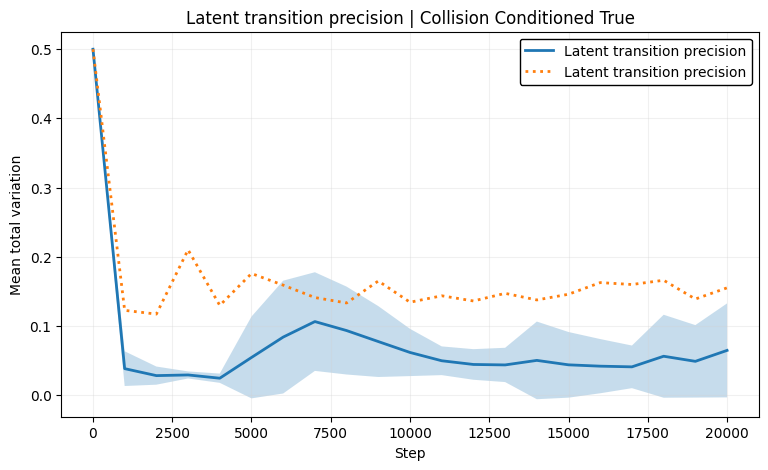

SummaryFrameBundle(raw_frames_by_series_name={'valid_only_yes': shape: (210, 3)
┌──────────────┬───────┬─────────────────────────────┐
│ run_id       ┆ step  ┆ latent_mean_total_variation │
│ ---          ┆ ---   ┆ ---                         │
│ str          ┆ i64   ┆ f64                         │
╞══════════════╪═══════╪═════════════════════════════╡
│ 06997ca9fc3e ┆ 1     ┆ 0.5                         │
│ 06997ca9fc3e ┆ 1000  ┆ 0.050885                    │
│ 06997ca9fc3e ┆ 2000  ┆ 0.042785                    │
│ 06997ca9fc3e ┆ 3000  ┆ 0.027882                    │
│ 06997ca9fc3e ┆ 4000  ┆ 0.036858                    │
│ …            ┆ …     ┆ …                           │
│ b185252b2108 ┆ 16000 ┆ 0.030197                    │
│ b185252b2108 ┆ 17000 ┆ 0.029614                    │
│ b185252b2108 ┆ 18000 ┆ 0.029273                    │
│ b185252b2108 ┆ 19000 ┆ 0.026303                    │
│ b185252b2108 ┆ 20000 ┆ 0.029146                    │
└──────────────┴───────┴────────────────

In [11]:
validity_ablation_plot = with_auto_title(
    plotting.NotebookPlot(
        shared_filters={
            "level": 21,
            "rand_prob": 0.3,
            "weight_memory": 1.0,
        },
        series=[
            plotting.NotebookSeries(
                name="valid_only_yes",
                metric_column_name="latent_mean_total_variation",
                label="Latent transition precision",
                filter_values={"mercury_split_sensory_raw_latent_valid": True},
                band_alpha=0.25,
            ),
            plotting.NotebookSeries(
                name="valid_only_no",
                metric_column_name="latent_mean_total_variation",
                label="Latent transition precision",
                filter_values={"mercury_split_sensory_raw_latent_valid": False},
                line_style=":",
                show_standard_deviation_band=False,
            ),
        ],
        y_axis_label="Mean total variation",
        use_grid=True,
    ),
    default_source_series_name="valid_only_yes",
)

plotting.display_notebook_plot(results, validity_ablation_plot)

Saved plot: results/current/notebook_plots/latent_edge_f1.png


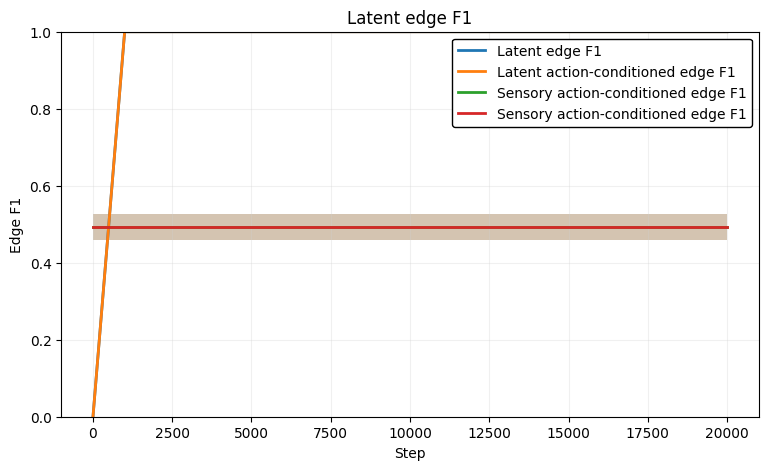

SummaryFrameBundle(raw_frames_by_series_name={'level_13_edge_F1': shape: (210, 3)
┌──────────────┬───────┬────────────────┐
│ run_id       ┆ step  ┆ latent_edge_f1 │
│ ---          ┆ ---   ┆ ---            │
│ str          ┆ i64   ┆ f64            │
╞══════════════╪═══════╪════════════════╡
│ 2045fe5ea517 ┆ 1     ┆ 0.0            │
│ 2045fe5ea517 ┆ 1000  ┆ 1.0            │
│ 2045fe5ea517 ┆ 2000  ┆ 1.0            │
│ 2045fe5ea517 ┆ 3000  ┆ 1.0            │
│ 2045fe5ea517 ┆ 4000  ┆ 1.0            │
│ …            ┆ …     ┆ …              │
│ fb8221d7f789 ┆ 16000 ┆ 1.0            │
│ fb8221d7f789 ┆ 17000 ┆ 1.0            │
│ fb8221d7f789 ┆ 18000 ┆ 1.0            │
│ fb8221d7f789 ┆ 19000 ┆ 1.0            │
│ fb8221d7f789 ┆ 20000 ┆ 1.0            │
└──────────────┴───────┴────────────────┘, 'level_13_action_edge_F1': shape: (210, 3)
┌──────────────┬───────┬─────────────────────────────────┐
│ run_id       ┆ step  ┆ latent_action_conditioned_edge… │
│ ---          ┆ ---   ┆ ---              

In [12]:
level_comparison_plot = with_auto_title(
    plotting.NotebookPlot(
        shared_filters={
            "rand_prob": 0.3,
            "weight_memory": 1.0,
            "mercury_split_sensory_raw_latent_valid": True,
        },
        series=[
            plotting.NotebookSeries(
                name="level_13_edge_F1",
                metric_column_name="latent_edge_f1",
                label="Latent edge F1",
                filter_values={"level": 13},
                band_alpha=0.20,
                show_standard_deviation_band=True,
            ),
            plotting.NotebookSeries(
                name="level_13_action_edge_F1",
                metric_column_name="latent_action_conditioned_edge_f1",
                label="Latent action-conditioned edge F1",
                filter_values={"level": 13},
                band_alpha=0.20,
                show_standard_deviation_band=True,
            ),
            plotting.NotebookSeries(
                name="level_13_edge_F1_sensory",
                metric_column_name="sensory_edge_f1",
                label="Sensory action-conditioned edge F1",
                filter_values={"level": 13},
                band_alpha=0.20,
                show_standard_deviation_band=True,
            ),
            plotting.NotebookSeries(
                name="level_13_action_edge_F1_sensory",
                metric_column_name="sensory_action_conditioned_edge_f1",
                label="Sensory action-conditioned edge F1",
                filter_values={"level": 13},
                band_alpha=0.20,
                show_standard_deviation_band=True,
            ),

        ],
        y_axis_label="Edge F1",
        y_limits=(0.0, 1.0),
        use_grid=True,
    ),
    default_source_series_name="level_13",
)

plotting.display_notebook_plot(results, level_comparison_plot)

$TV_{mean}$ | Level 13 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/tv_mean_level_13_persistence_1_0_w_mem_0_8_collision_conditioned_true.png


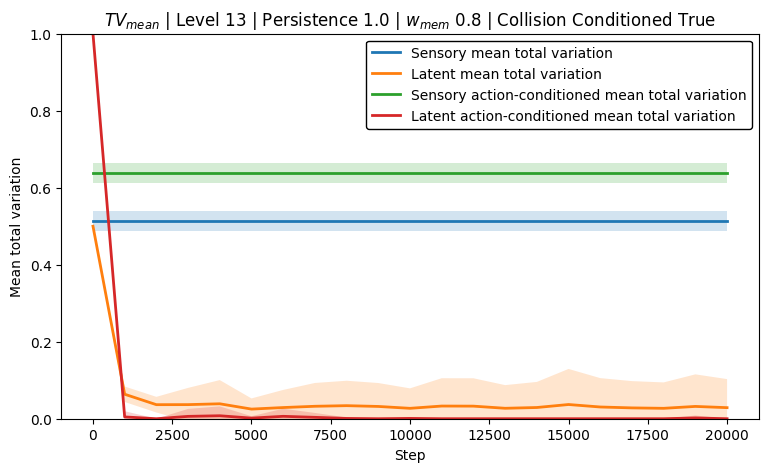

$TV_{mean}$ | Level 13 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/tv_mean_level_13_persistence_1_0_w_mem_0_8_collision_conditioned_false.png


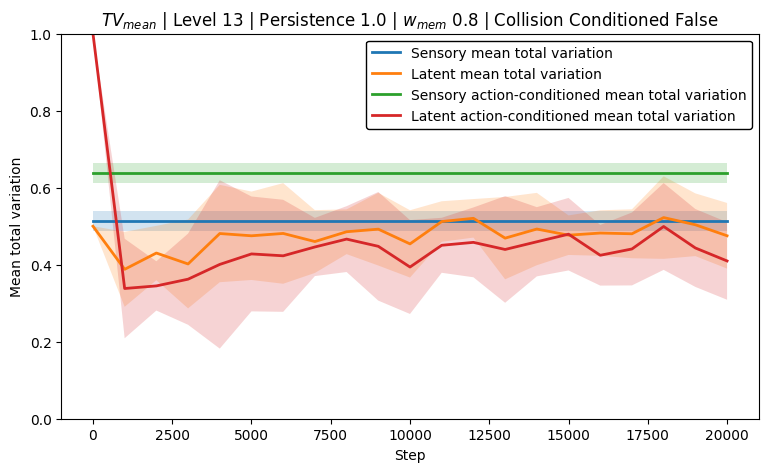

$TV_{mean}$ | Level 13 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/tv_mean_level_13_persistence_0_7_w_mem_0_8_collision_conditioned_true.png


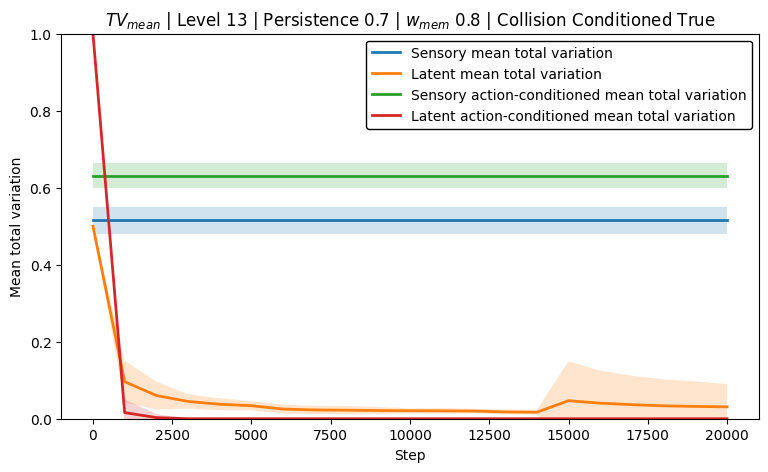

$TV_{mean}$ | Level 13 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/tv_mean_level_13_persistence_0_7_w_mem_0_8_collision_conditioned_false.png


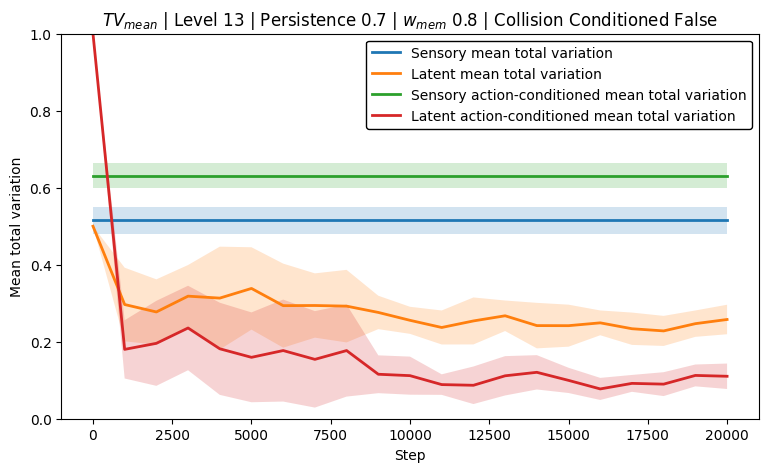

$TV_{mean}$ | Level 13 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/tv_mean_level_13_persistence_1_0_w_mem_1_0_collision_conditioned_true.png


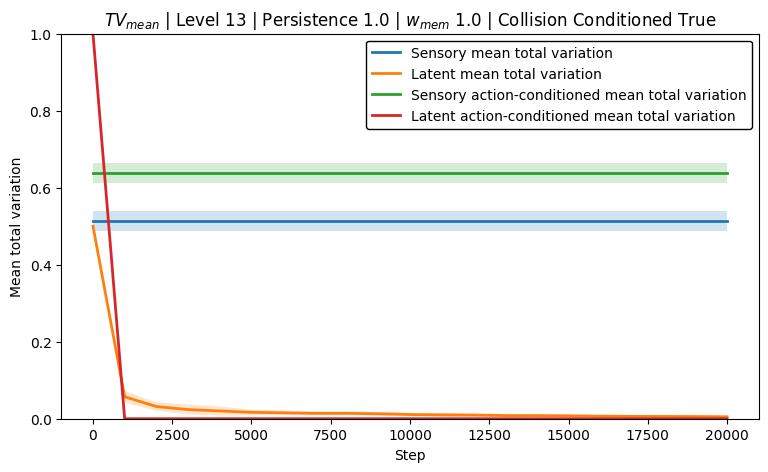

$TV_{mean}$ | Level 13 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/tv_mean_level_13_persistence_1_0_w_mem_1_0_collision_conditioned_false.png


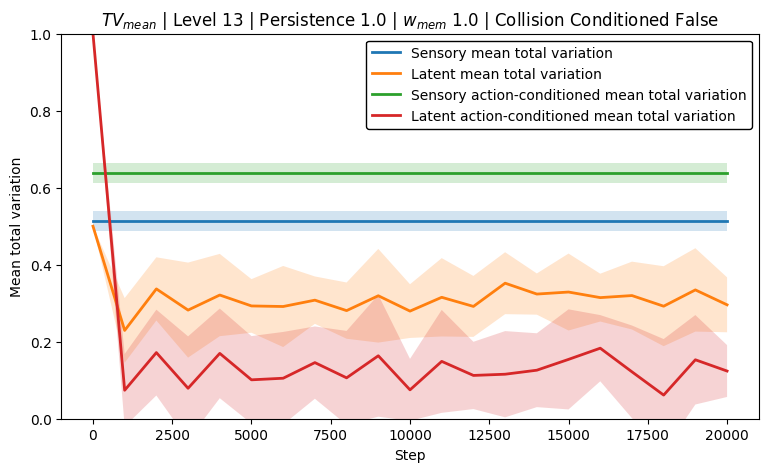

$TV_{mean}$ | Level 13 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/tv_mean_level_13_persistence_0_7_w_mem_1_0_collision_conditioned_true.png


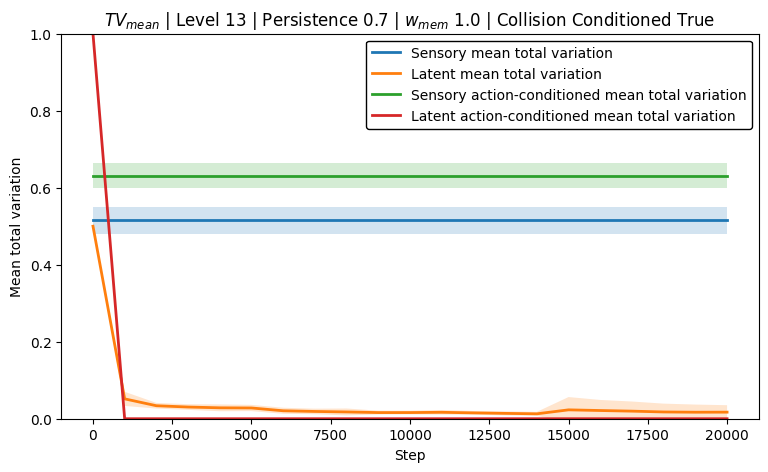

$TV_{mean}$ | Level 13 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/tv_mean_level_13_persistence_0_7_w_mem_1_0_collision_conditioned_false.png


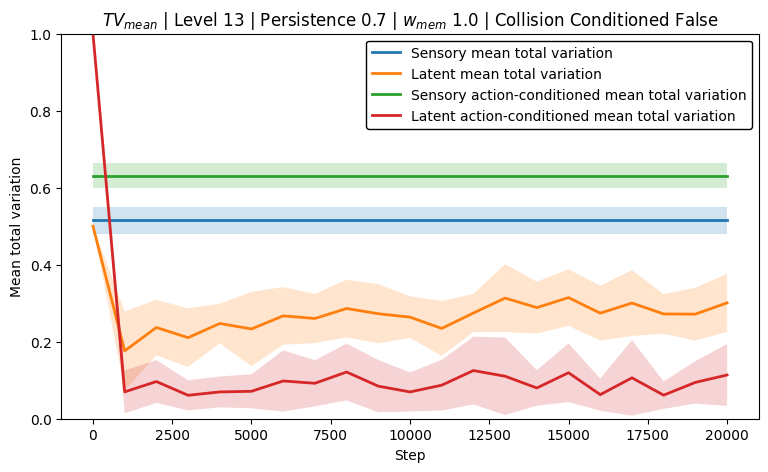

$TV_{mean}$ | Level 20 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/tv_mean_level_20_persistence_1_0_w_mem_0_8_collision_conditioned_true.png


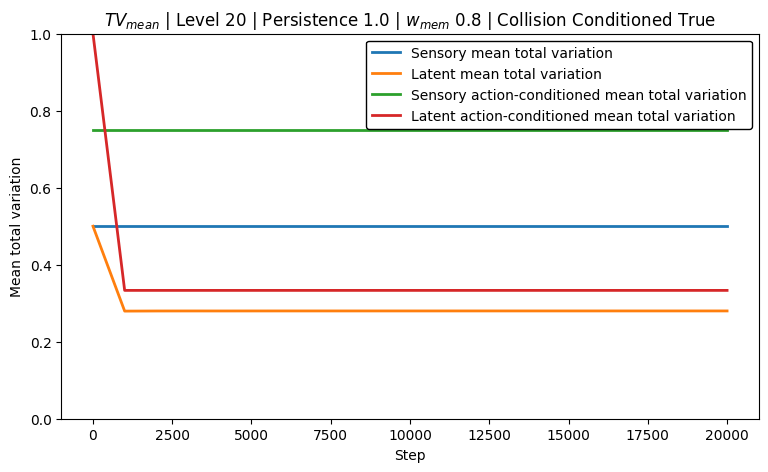

$TV_{mean}$ | Level 20 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/tv_mean_level_20_persistence_1_0_w_mem_0_8_collision_conditioned_false.png


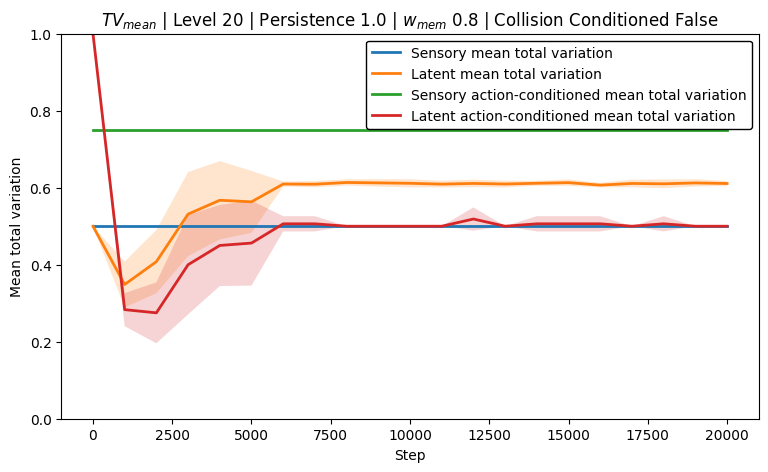

$TV_{mean}$ | Level 20 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/tv_mean_level_20_persistence_0_7_w_mem_0_8_collision_conditioned_true.png


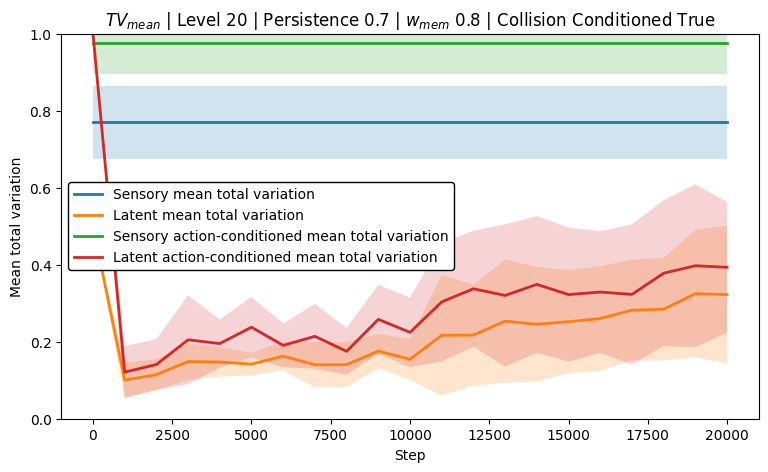

$TV_{mean}$ | Level 20 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/tv_mean_level_20_persistence_0_7_w_mem_0_8_collision_conditioned_false.png


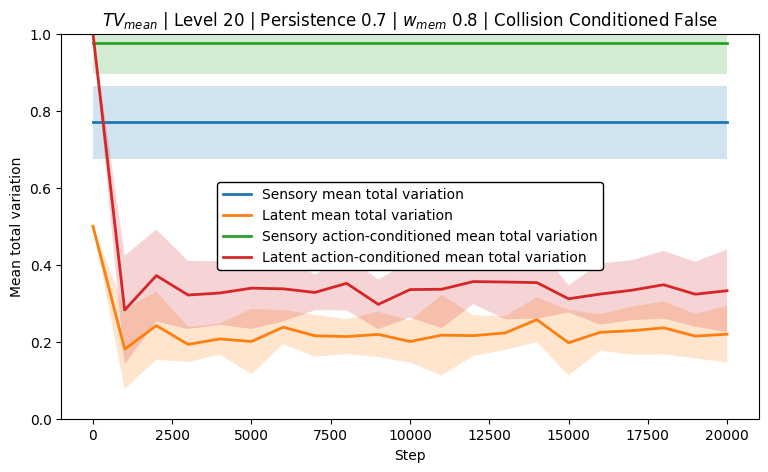

$TV_{mean}$ | Level 20 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/tv_mean_level_20_persistence_1_0_w_mem_1_0_collision_conditioned_true.png


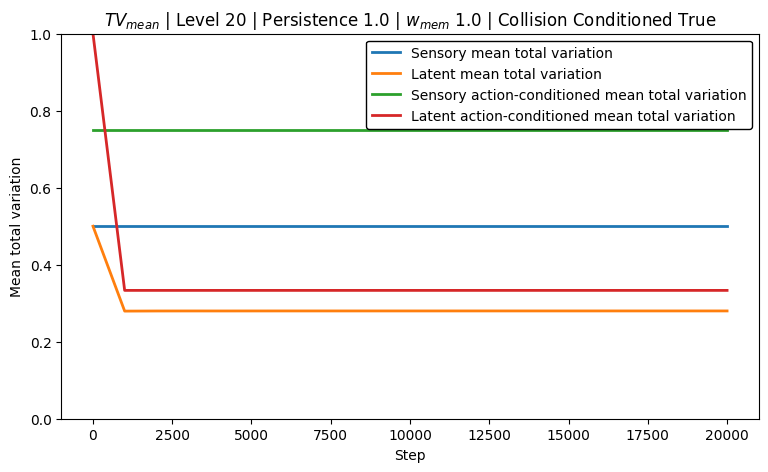

$TV_{mean}$ | Level 20 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/tv_mean_level_20_persistence_1_0_w_mem_1_0_collision_conditioned_false.png


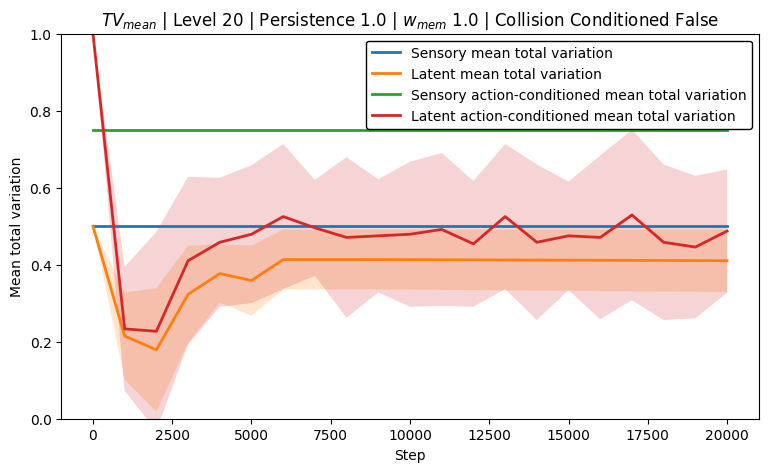

$TV_{mean}$ | Level 20 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/tv_mean_level_20_persistence_0_7_w_mem_1_0_collision_conditioned_true.png


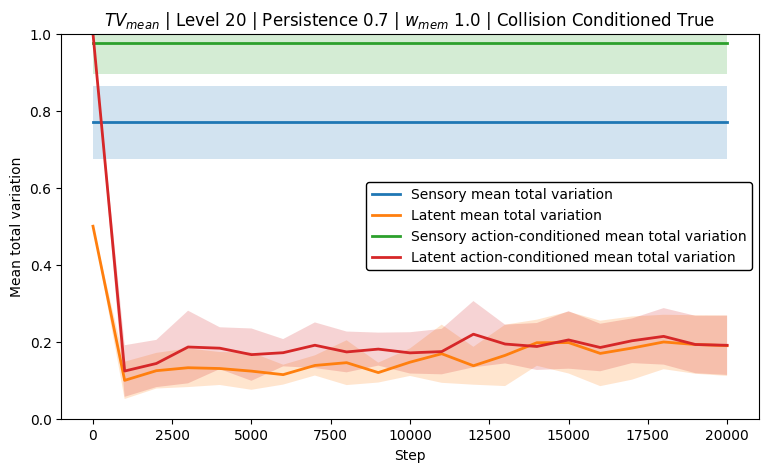

$TV_{mean}$ | Level 20 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/tv_mean_level_20_persistence_0_7_w_mem_1_0_collision_conditioned_false.png


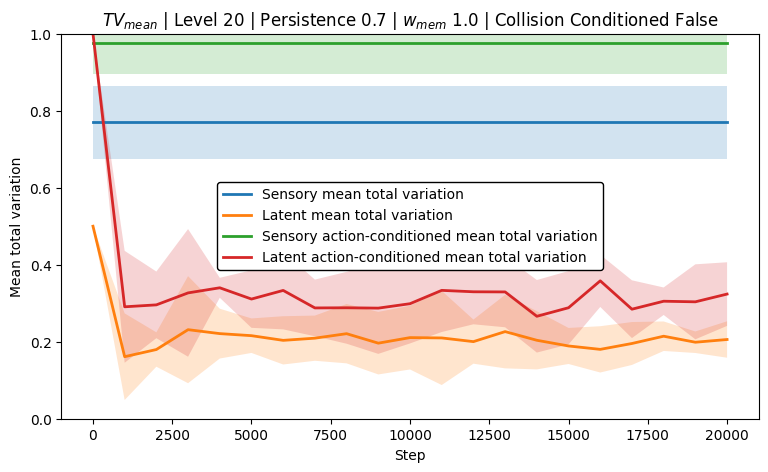

$TV_{mean}$ | Level 21 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/tv_mean_level_21_persistence_1_0_w_mem_0_8_collision_conditioned_true.png


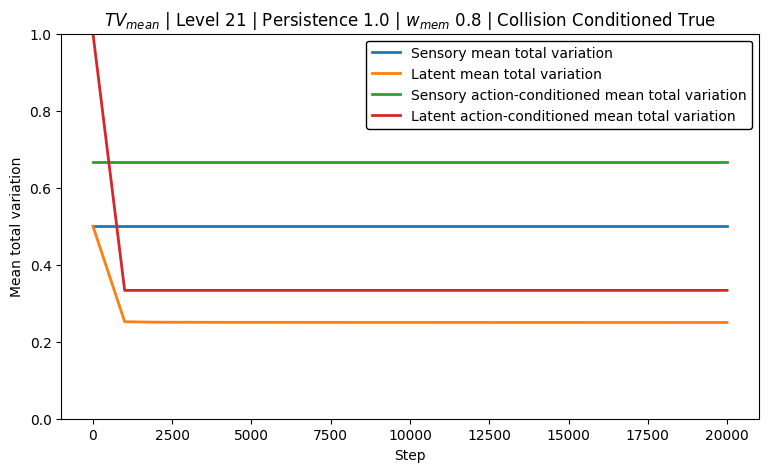

$TV_{mean}$ | Level 21 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/tv_mean_level_21_persistence_1_0_w_mem_0_8_collision_conditioned_false.png


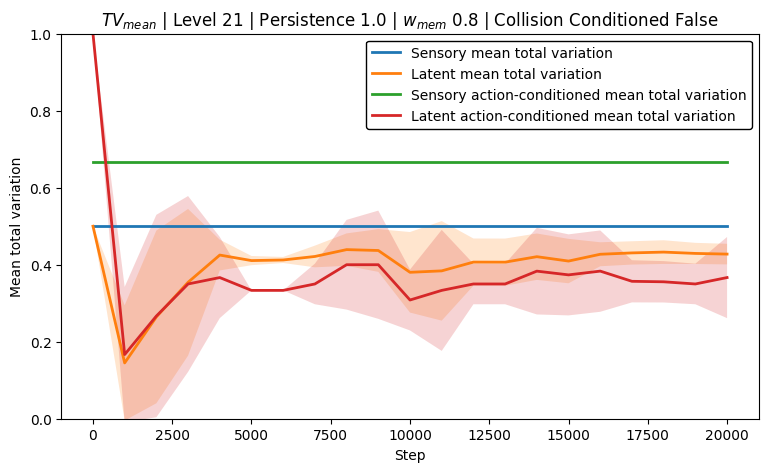

$TV_{mean}$ | Level 21 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/tv_mean_level_21_persistence_0_7_w_mem_0_8_collision_conditioned_true.png


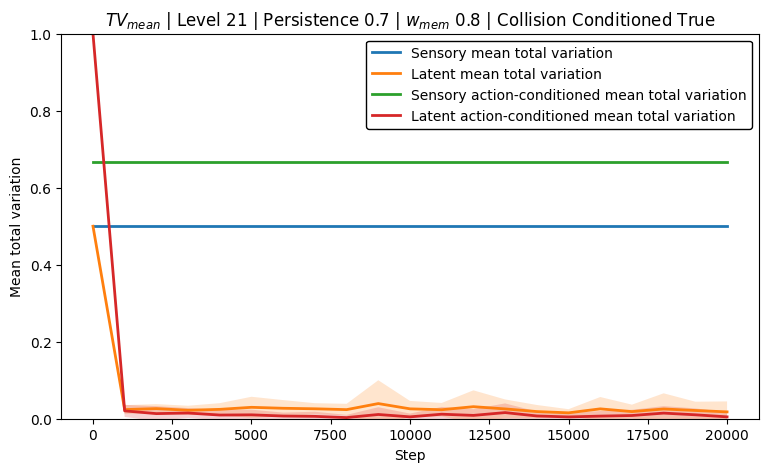

$TV_{mean}$ | Level 21 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/tv_mean_level_21_persistence_0_7_w_mem_0_8_collision_conditioned_false.png


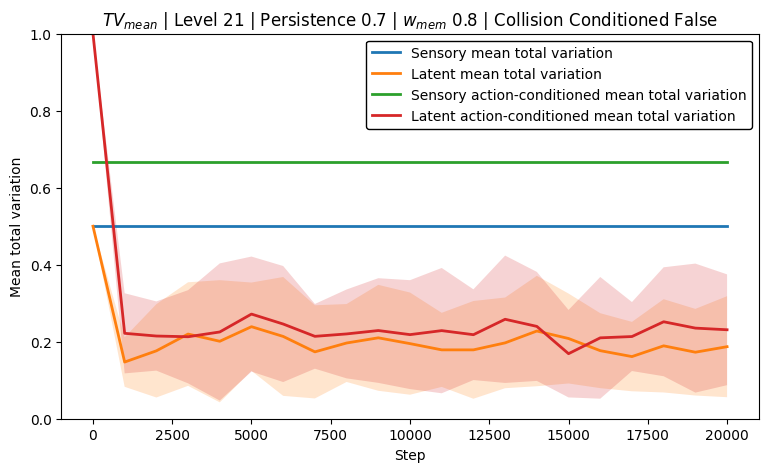

$TV_{mean}$ | Level 21 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/tv_mean_level_21_persistence_1_0_w_mem_1_0_collision_conditioned_true.png


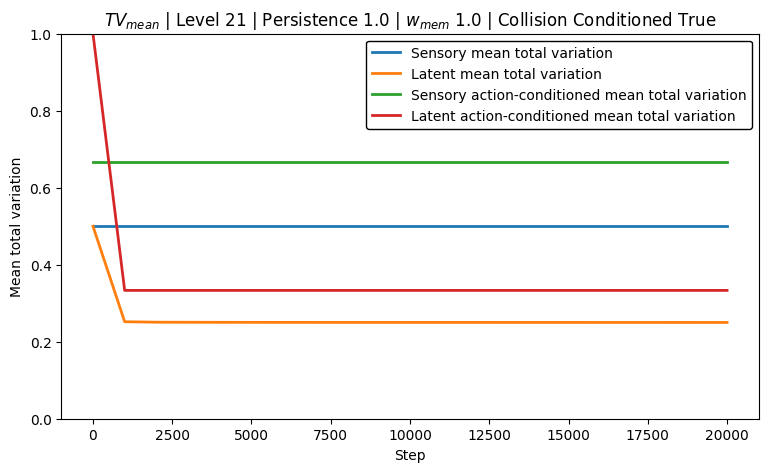

$TV_{mean}$ | Level 21 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/tv_mean_level_21_persistence_1_0_w_mem_1_0_collision_conditioned_false.png


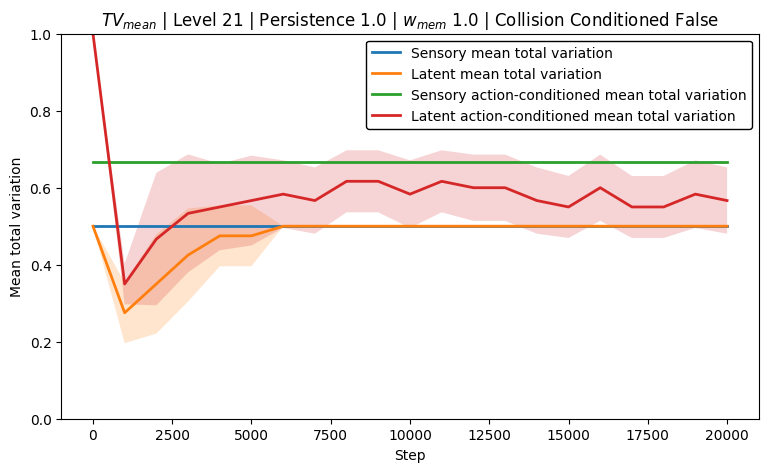

$TV_{mean}$ | Level 21 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/tv_mean_level_21_persistence_0_7_w_mem_1_0_collision_conditioned_true.png


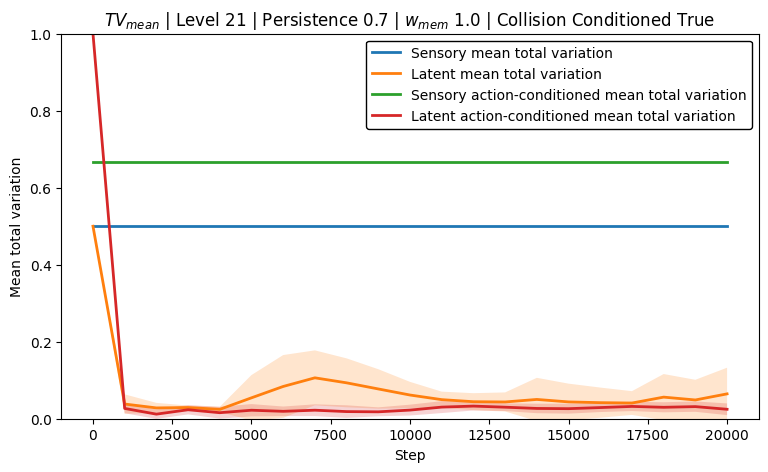

$TV_{mean}$ | Level 21 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/tv_mean_level_21_persistence_0_7_w_mem_1_0_collision_conditioned_false.png


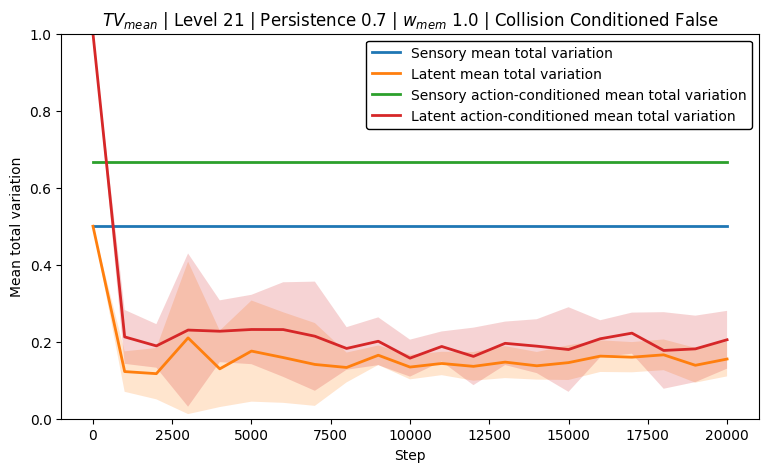

In [13]:
levels = [13,20,21]
weights_mem = [0.8, 1.0]
rand_probs = [0.0, 0.3]
valid_onlys = [True, False]
for level in levels:
    for weight_mem in weights_mem:
        for rand_prob in rand_probs:
            for valid_only in valid_onlys:
                level_comparison_plot = plotting.NotebookPlot(
                        shared_filters={
                            "rand_prob": rand_prob,
                            "weight_memory": weight_mem,
                            "mercury_split_sensory_raw_latent_valid": valid_only,
                            "level": level,
                        },
                        title_spec=plotting.NotebookTitleSpec(
                            metric_label_mode="custom",
                            metric_label_text="$TV_{mean}$",
                            separator=" | ",
                            parameter_specs=[
                                plotting.build_title_parameter_spec(
                                    plotting.CANONICAL_TITLE_PARAMETERS[parameter_name]
                                )
                                for parameter_name in plotting.CANONICAL_TITLE_PARAMETER_ORDER
                            ],
                        ),
                        series=[
                           plotting.NotebookSeries(
                                name="sensory_mean_total_variation",
                                metric_column_name="sensory_mean_total_variation",
                                label="Sensory mean total variation",
                                band_alpha=0.20,
                                show_standard_deviation_band=True,
                            ),
                            plotting.NotebookSeries(
                                name="latent mean_total_variation",
                                metric_column_name="latent_mean_total_variation",
                                label="Latent mean total variation",
                                band_alpha=0.20,
                                show_standard_deviation_band=True,
                            ),
                           plotting.NotebookSeries(
                                name="sensory_action_conditioned_mean_total_variation",
                                metric_column_name="sensory_action_conditioned_mean_total_variation",
                                label="Sensory action-conditioned mean total variation",
                                band_alpha=0.20,
                                show_standard_deviation_band=True,
                            ),
                            plotting.NotebookSeries(
                                name="latent_action_conditioned_mean_total_variation",
                                metric_column_name="latent_action_conditioned_mean_total_variation",
                                label="Latent action-conditioned mean total variation",
                                band_alpha=0.20,
                                show_standard_deviation_band=True,
                            ),



                        ],
                        y_axis_label="Mean total variation",
                        y_limits=(0.0, 1.0),
                        use_grid=False,
                    )
                print(plotting.generate_notebook_plot_title(level_comparison_plot))

                plotting.display_notebook_plot(results, level_comparison_plot)

Edge F1 | Level 13 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/edge_f1_level_13_persistence_1_0_w_mem_0_8_collision_conditioned_true.png


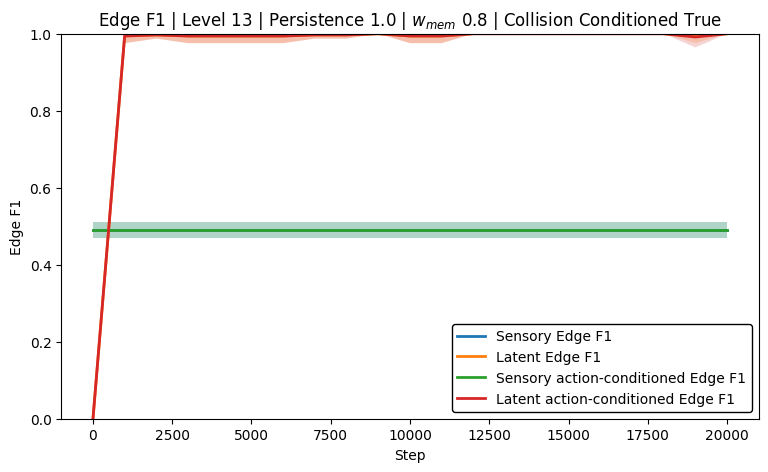

Edge F1 | Level 13 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/edge_f1_level_13_persistence_1_0_w_mem_0_8_collision_conditioned_false.png


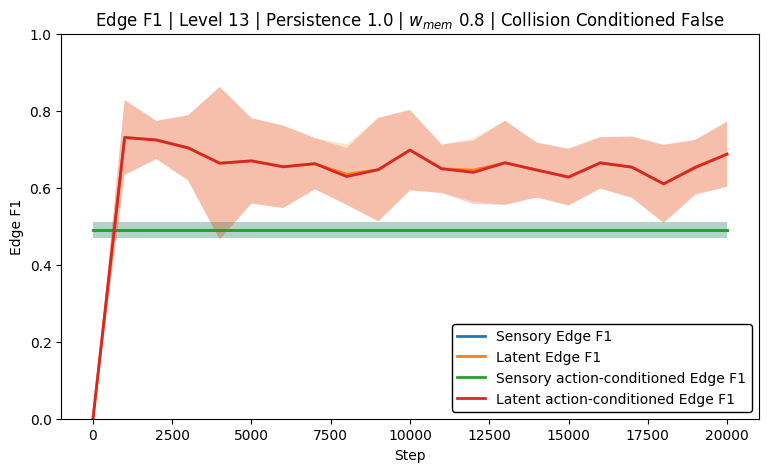

Edge F1 | Level 13 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/edge_f1_level_13_persistence_0_7_w_mem_0_8_collision_conditioned_true.png


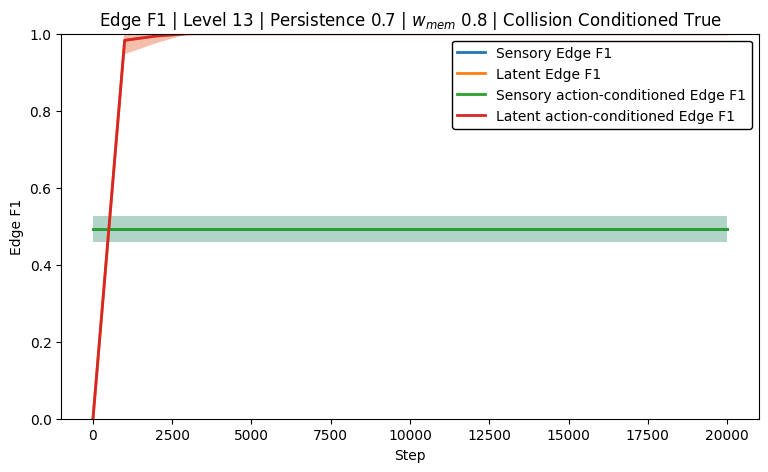

Edge F1 | Level 13 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/edge_f1_level_13_persistence_0_7_w_mem_0_8_collision_conditioned_false.png


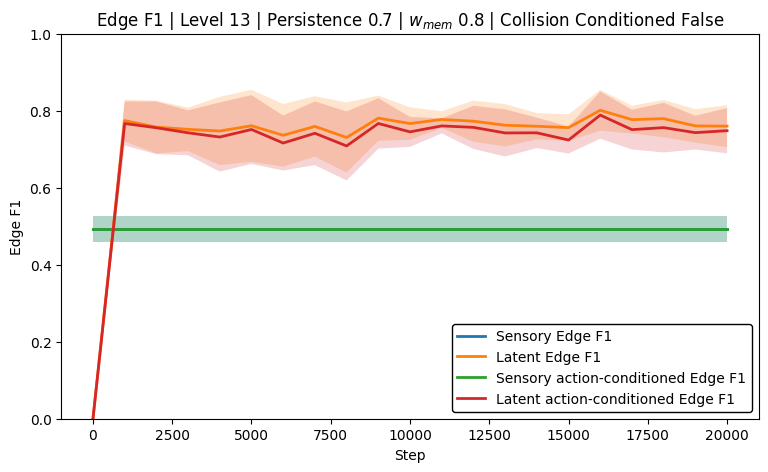

Edge F1 | Level 13 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/edge_f1_level_13_persistence_1_0_w_mem_1_0_collision_conditioned_true.png


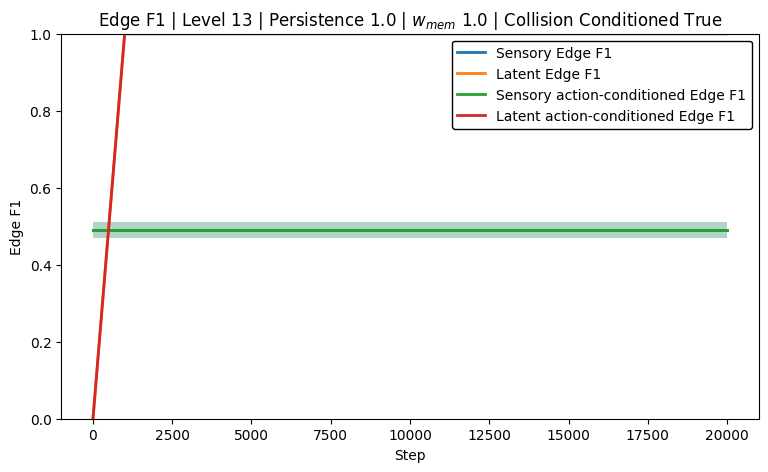

Edge F1 | Level 13 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/edge_f1_level_13_persistence_1_0_w_mem_1_0_collision_conditioned_false.png


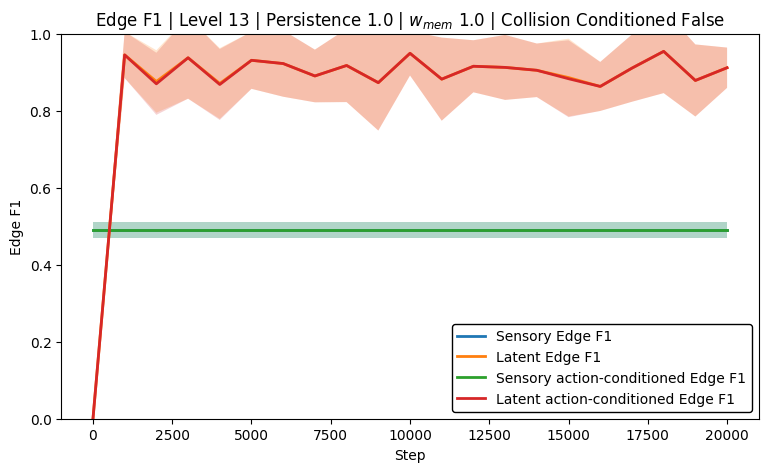

Edge F1 | Level 13 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/edge_f1_level_13_persistence_0_7_w_mem_1_0_collision_conditioned_true.png


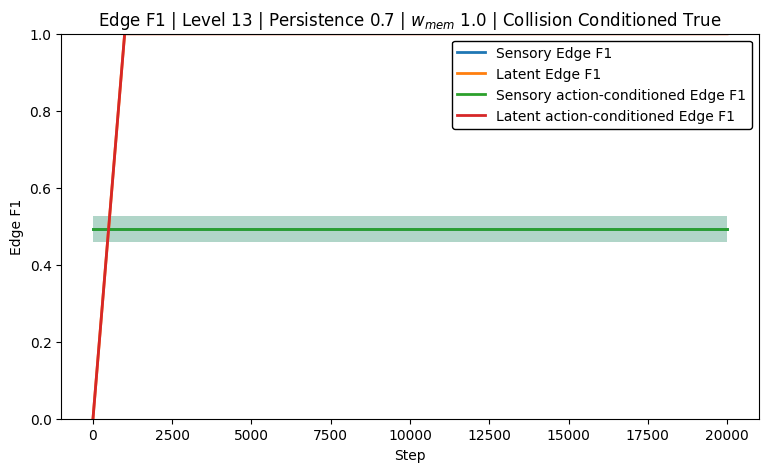

Edge F1 | Level 13 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/edge_f1_level_13_persistence_0_7_w_mem_1_0_collision_conditioned_false.png


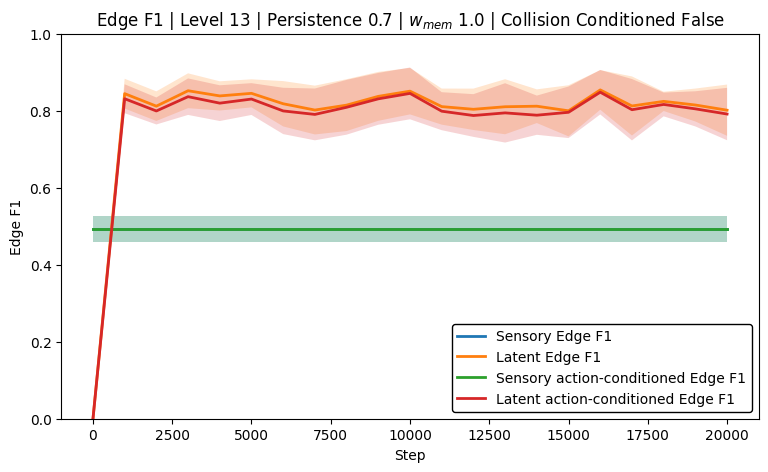

Edge F1 | Level 20 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/edge_f1_level_20_persistence_1_0_w_mem_0_8_collision_conditioned_true.png


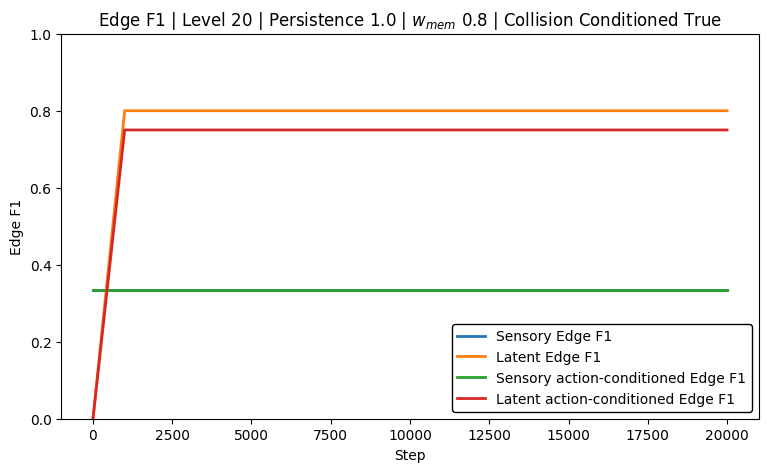

Edge F1 | Level 20 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/edge_f1_level_20_persistence_1_0_w_mem_0_8_collision_conditioned_false.png


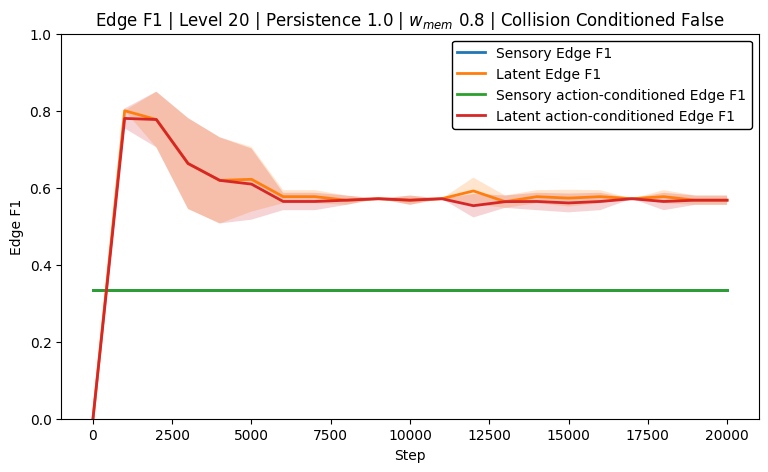

Edge F1 | Level 20 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/edge_f1_level_20_persistence_0_7_w_mem_0_8_collision_conditioned_true.png


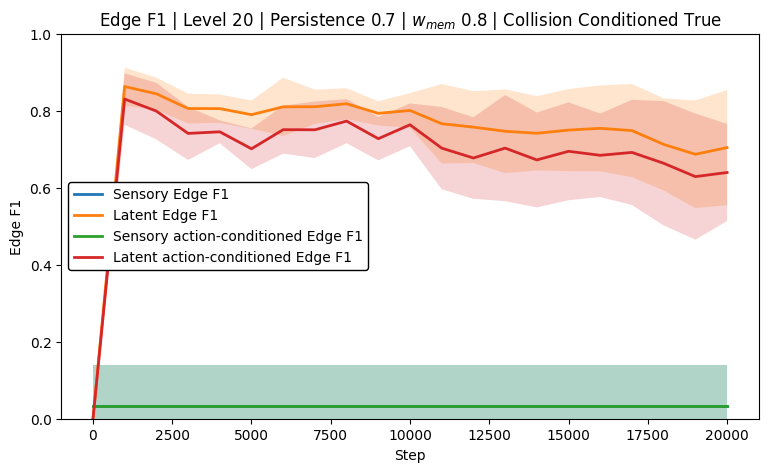

Edge F1 | Level 20 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/edge_f1_level_20_persistence_0_7_w_mem_0_8_collision_conditioned_false.png


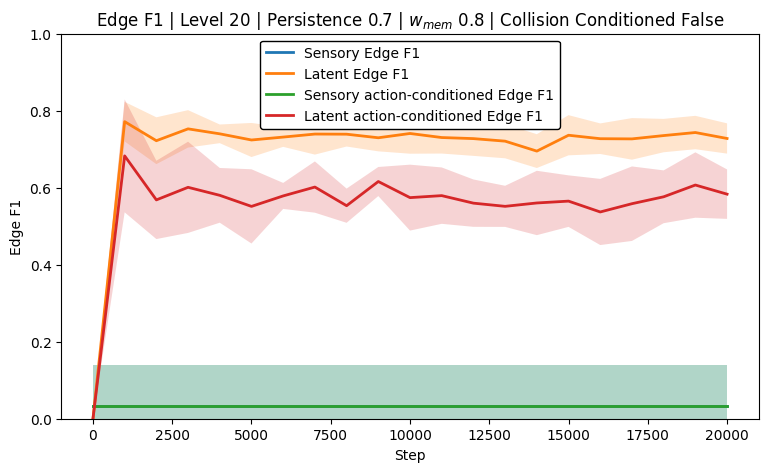

Edge F1 | Level 20 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/edge_f1_level_20_persistence_1_0_w_mem_1_0_collision_conditioned_true.png


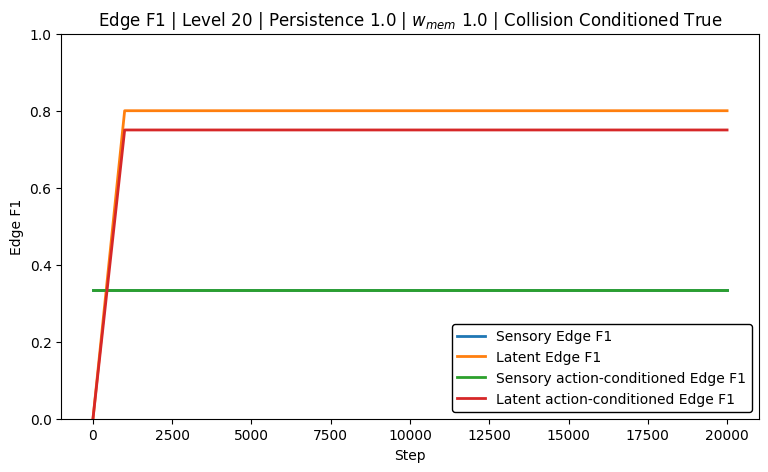

Edge F1 | Level 20 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/edge_f1_level_20_persistence_1_0_w_mem_1_0_collision_conditioned_false.png


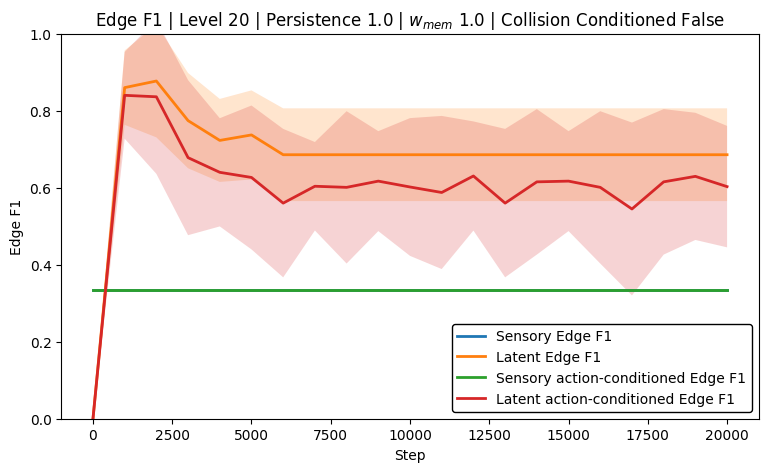

Edge F1 | Level 20 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/edge_f1_level_20_persistence_0_7_w_mem_1_0_collision_conditioned_true.png


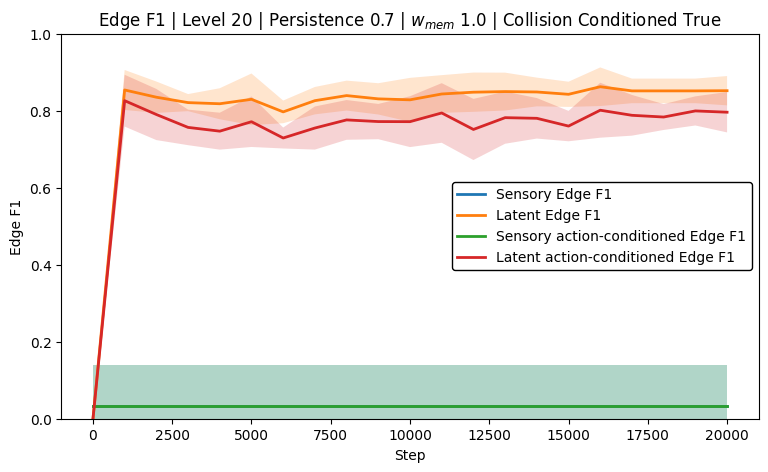

Edge F1 | Level 20 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/edge_f1_level_20_persistence_0_7_w_mem_1_0_collision_conditioned_false.png


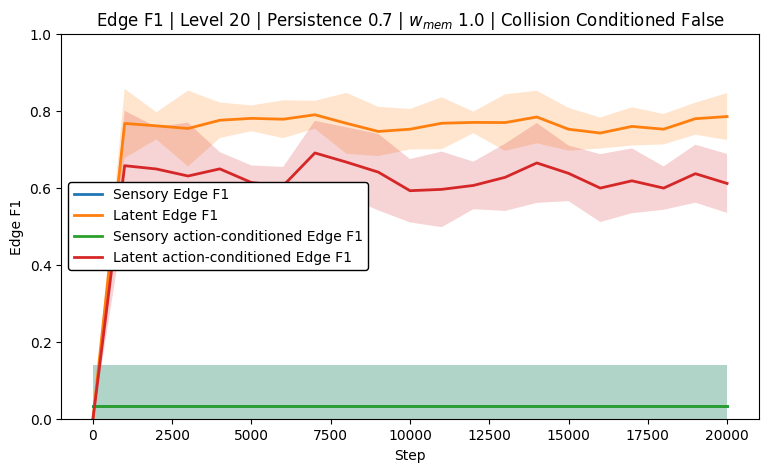

Edge F1 | Level 21 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/edge_f1_level_21_persistence_1_0_w_mem_0_8_collision_conditioned_true.png


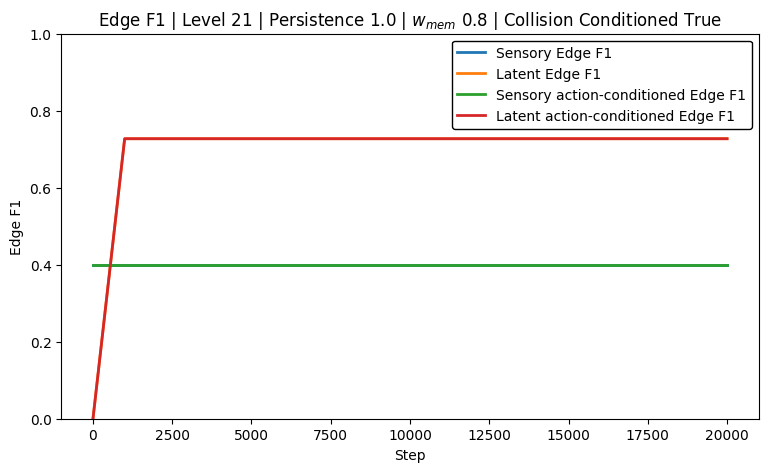

Edge F1 | Level 21 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/edge_f1_level_21_persistence_1_0_w_mem_0_8_collision_conditioned_false.png


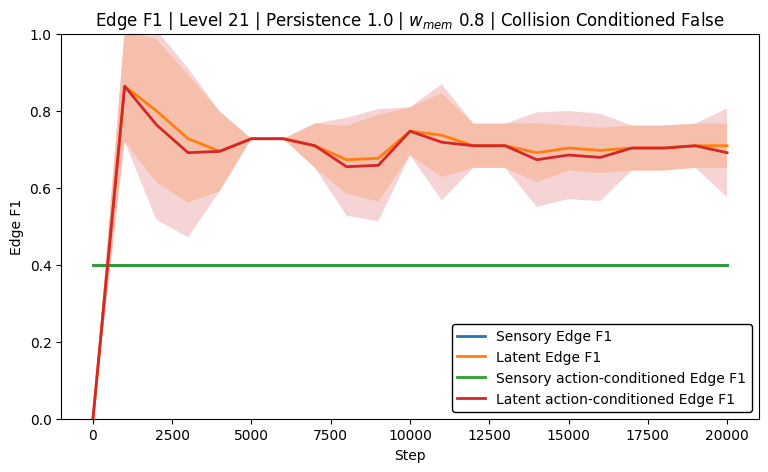

Edge F1 | Level 21 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/edge_f1_level_21_persistence_0_7_w_mem_0_8_collision_conditioned_true.png


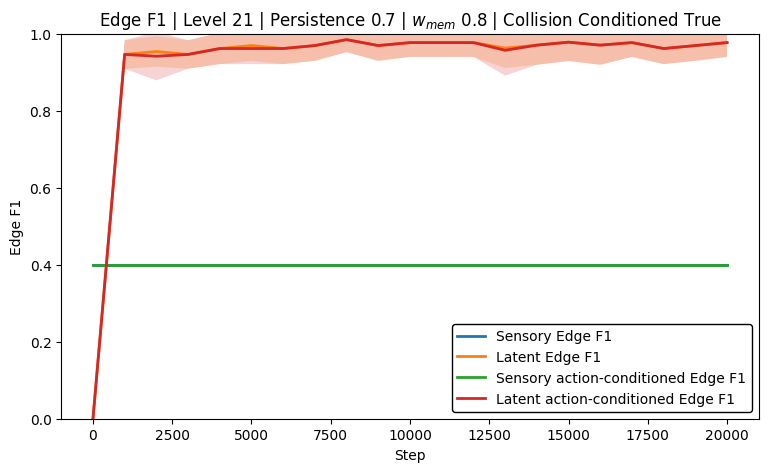

Edge F1 | Level 21 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/edge_f1_level_21_persistence_0_7_w_mem_0_8_collision_conditioned_false.png


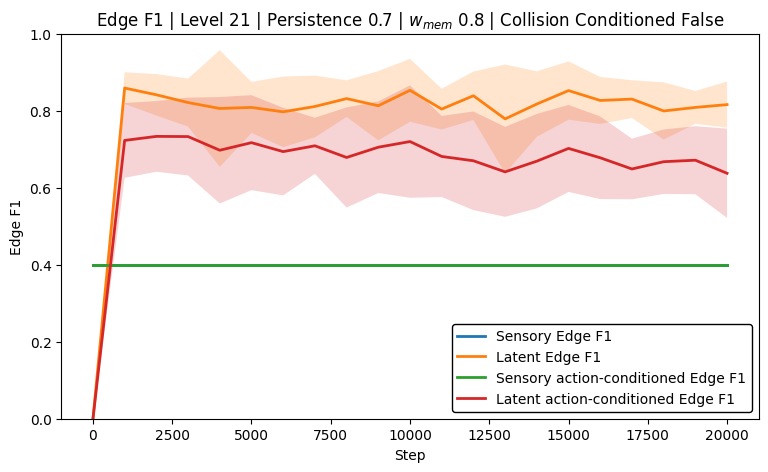

Edge F1 | Level 21 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/edge_f1_level_21_persistence_1_0_w_mem_1_0_collision_conditioned_true.png


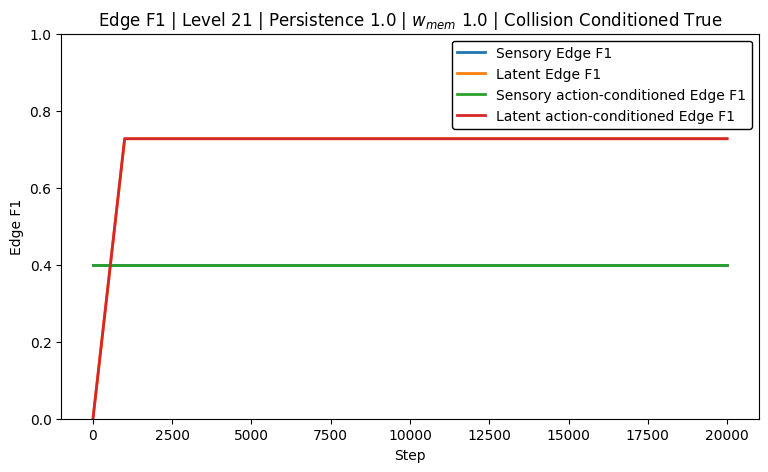

Edge F1 | Level 21 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/edge_f1_level_21_persistence_1_0_w_mem_1_0_collision_conditioned_false.png


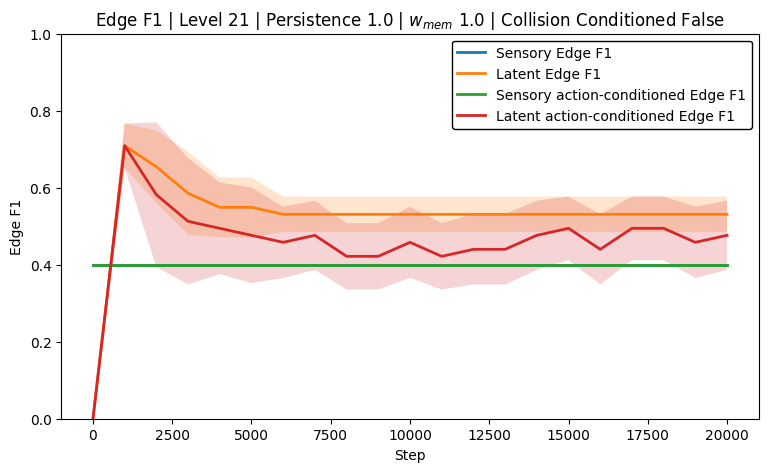

Edge F1 | Level 21 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/edge_f1_level_21_persistence_0_7_w_mem_1_0_collision_conditioned_true.png


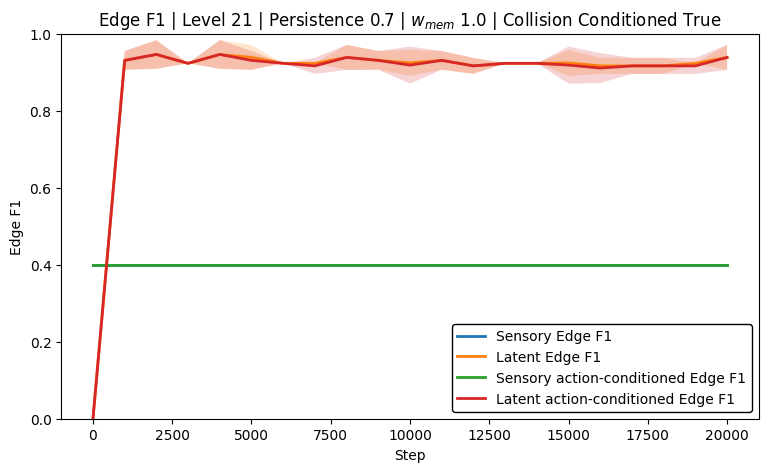

Edge F1 | Level 21 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/edge_f1_level_21_persistence_0_7_w_mem_1_0_collision_conditioned_false.png


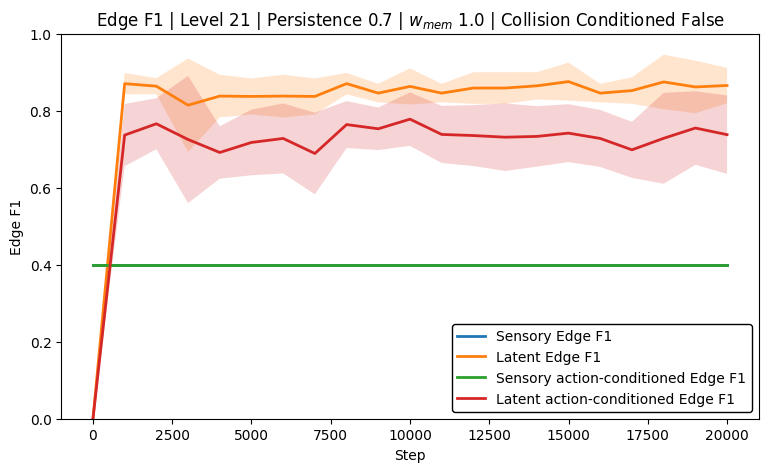

In [14]:
levels = [13,20,21]
weights_mem = [0.8, 1.0]
rand_probs = [0.0, 0.3]
valid_onlys = [True, False]
for level in levels:
    for weight_mem in weights_mem:
        for rand_prob in rand_probs:
            for valid_only in valid_onlys:
                level_comparison_plot = plotting.NotebookPlot(
                        shared_filters={
                            "rand_prob": rand_prob,
                            "weight_memory": weight_mem,
                            "mercury_split_sensory_raw_latent_valid": valid_only,
                            "level": level,
                        },
                        title_spec=plotting.NotebookTitleSpec(
                            metric_label_mode="custom",
                            metric_label_text="Edge F1",
                            separator=" | ",
                            parameter_specs=[
                                plotting.build_title_parameter_spec(
                                    plotting.CANONICAL_TITLE_PARAMETERS[parameter_name]
                                )
                                for parameter_name in plotting.CANONICAL_TITLE_PARAMETER_ORDER
                            ],
                        ),
                        series=[
                           plotting.NotebookSeries(
                                name="sensory_edge_F1",
                                metric_column_name="sensory_edge_f1",
                                label="Sensory Edge F1",
                                band_alpha=0.20,
                                show_standard_deviation_band=True,
                            ),
                            plotting.NotebookSeries(
                                name="latent mean_total_variation",
                                metric_column_name="latent_edge_f1",
                                label="Latent Edge F1",
                                band_alpha=0.20,
                                show_standard_deviation_band=True,
                            ),
                           plotting.NotebookSeries(
                                name="sensory_action_conditioned_edge_F1",
                                metric_column_name="sensory_action_conditioned_edge_f1",
                                label="Sensory action-conditioned Edge F1",
                                band_alpha=0.20,
                                show_standard_deviation_band=True,
                            ),
                            plotting.NotebookSeries(
                                name="latent_action_conditioned_edge_F1",
                                metric_column_name="latent_action_conditioned_edge_f1",
                                label="Latent action-conditioned Edge F1",
                                band_alpha=0.20,
                                show_standard_deviation_band=True,
                            ),



                        ],
                        y_axis_label="Edge F1",
                        y_limits=(0.0, 1.0),
                        use_grid=False,
                    )
                print(plotting.generate_notebook_plot_title(level_comparison_plot))

                plotting.display_notebook_plot(results, level_comparison_plot)

State Representation Precision | Level 13 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/state_representation_precision_level_13_persistence_1_0_w_mem_0_8_collision_conditioned_true.png


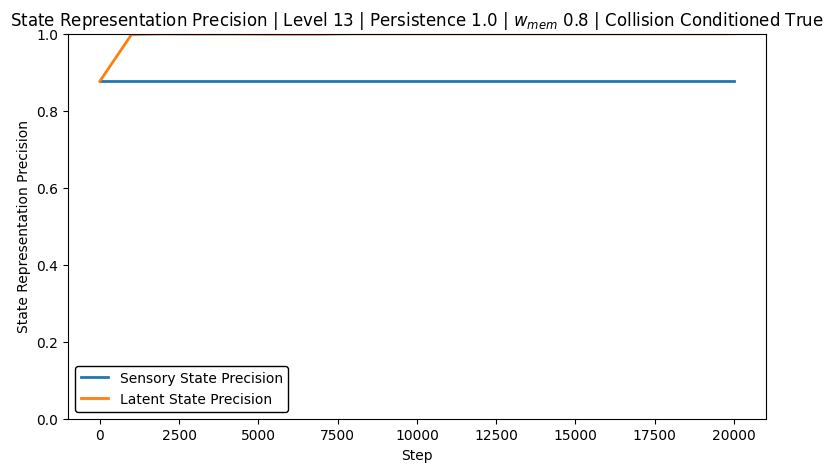

State Representation Precision | Level 13 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/state_representation_precision_level_13_persistence_1_0_w_mem_0_8_collision_conditioned_false.png


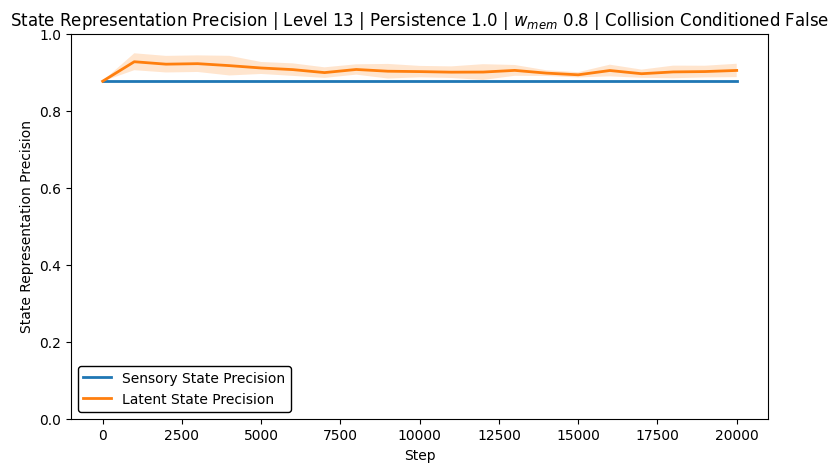

State Representation Precision | Level 13 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/state_representation_precision_level_13_persistence_0_7_w_mem_0_8_collision_conditioned_true.png


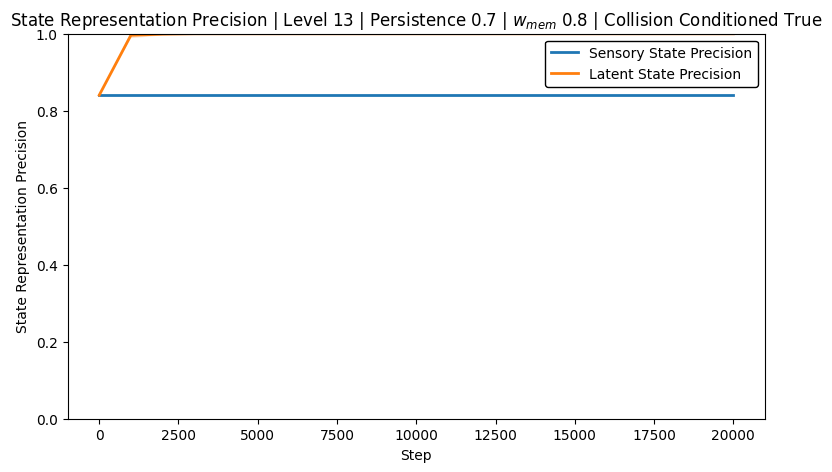

State Representation Precision | Level 13 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/state_representation_precision_level_13_persistence_0_7_w_mem_0_8_collision_conditioned_false.png


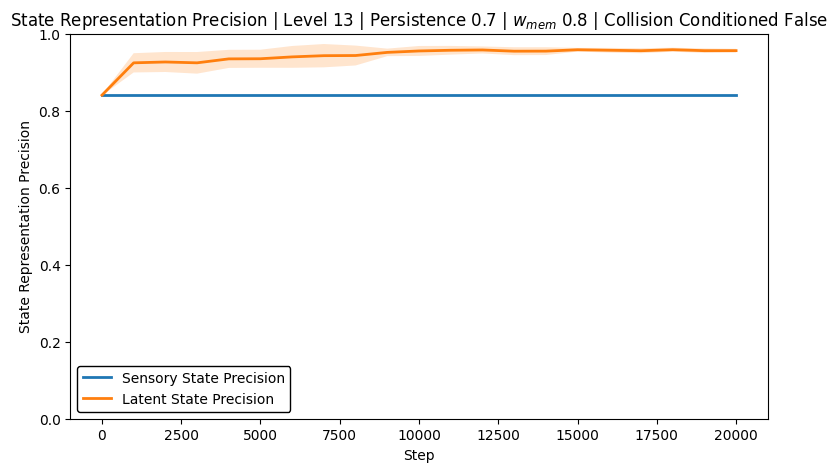

State Representation Precision | Level 13 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/state_representation_precision_level_13_persistence_1_0_w_mem_1_0_collision_conditioned_true.png


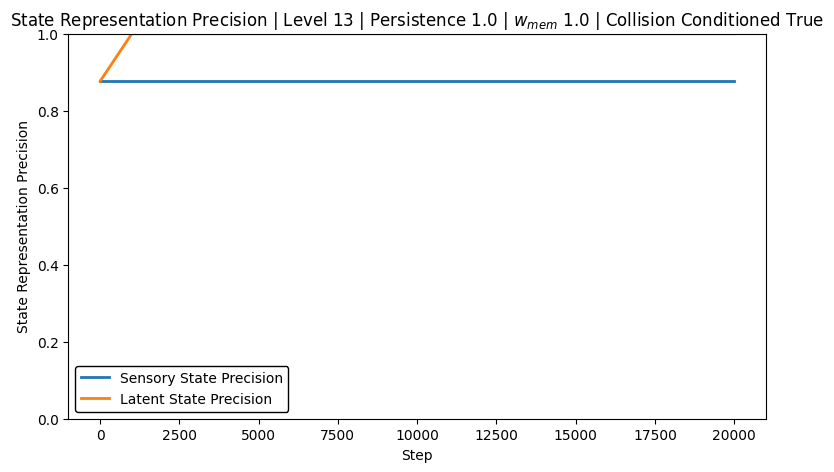

State Representation Precision | Level 13 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/state_representation_precision_level_13_persistence_1_0_w_mem_1_0_collision_conditioned_false.png


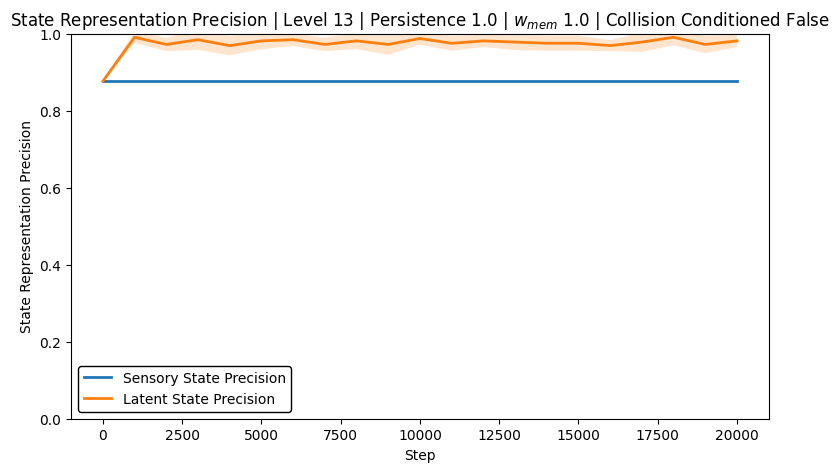

State Representation Precision | Level 13 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/state_representation_precision_level_13_persistence_0_7_w_mem_1_0_collision_conditioned_true.png


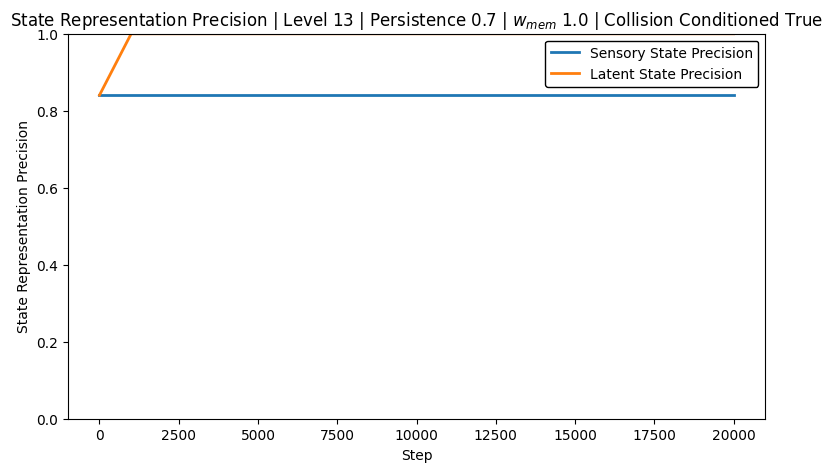

State Representation Precision | Level 13 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/state_representation_precision_level_13_persistence_0_7_w_mem_1_0_collision_conditioned_false.png


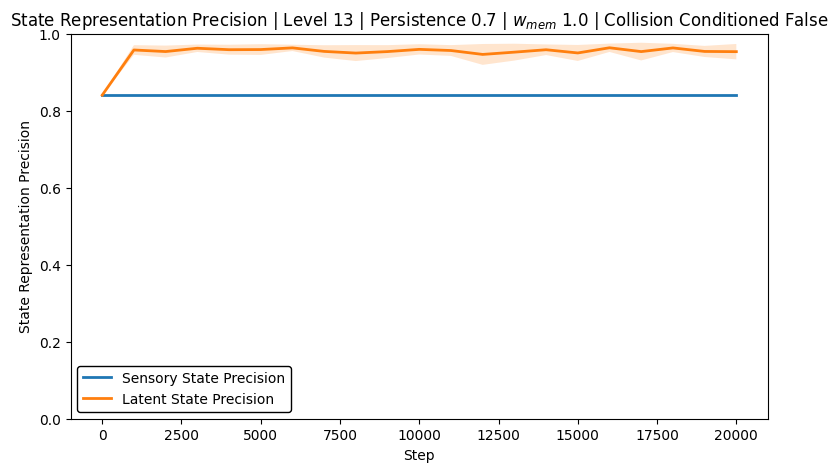

State Representation Precision | Level 20 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/state_representation_precision_level_20_persistence_1_0_w_mem_0_8_collision_conditioned_true.png


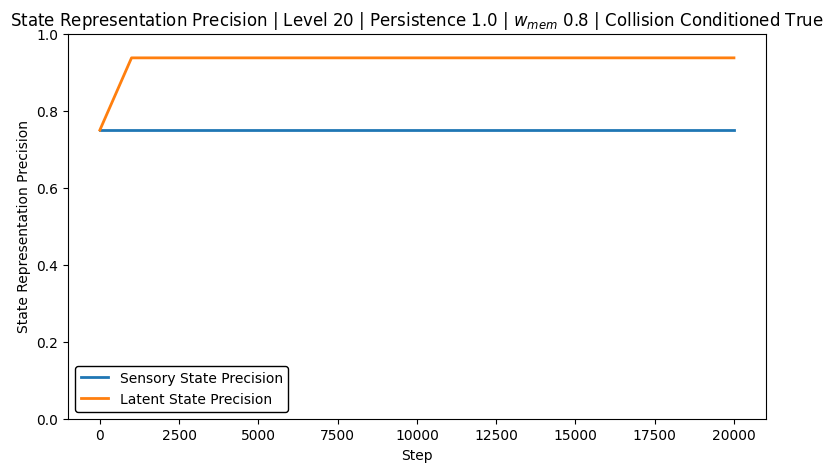

State Representation Precision | Level 20 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/state_representation_precision_level_20_persistence_1_0_w_mem_0_8_collision_conditioned_false.png


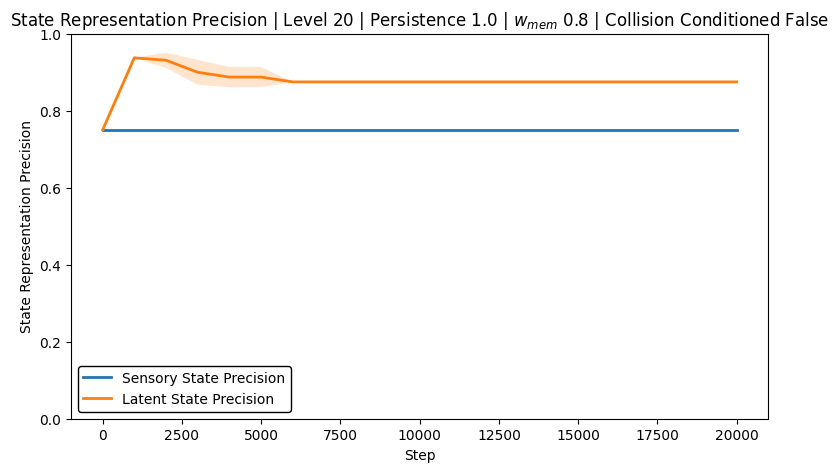

State Representation Precision | Level 20 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/state_representation_precision_level_20_persistence_0_7_w_mem_0_8_collision_conditioned_true.png


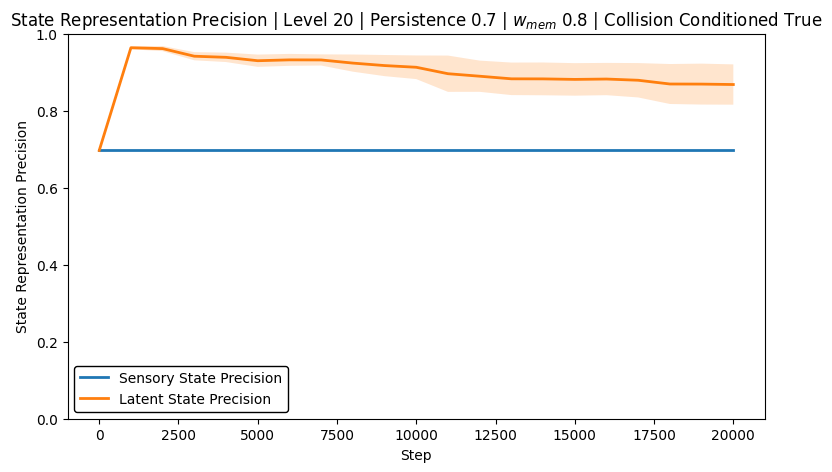

State Representation Precision | Level 20 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/state_representation_precision_level_20_persistence_0_7_w_mem_0_8_collision_conditioned_false.png


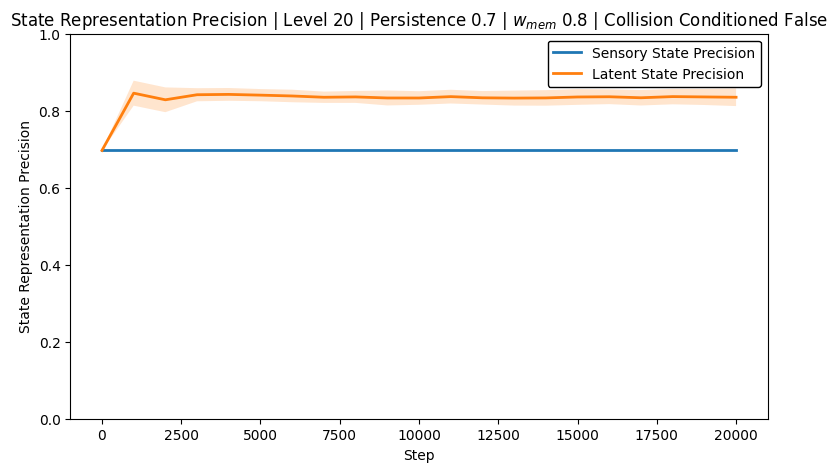

State Representation Precision | Level 20 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/state_representation_precision_level_20_persistence_1_0_w_mem_1_0_collision_conditioned_true.png


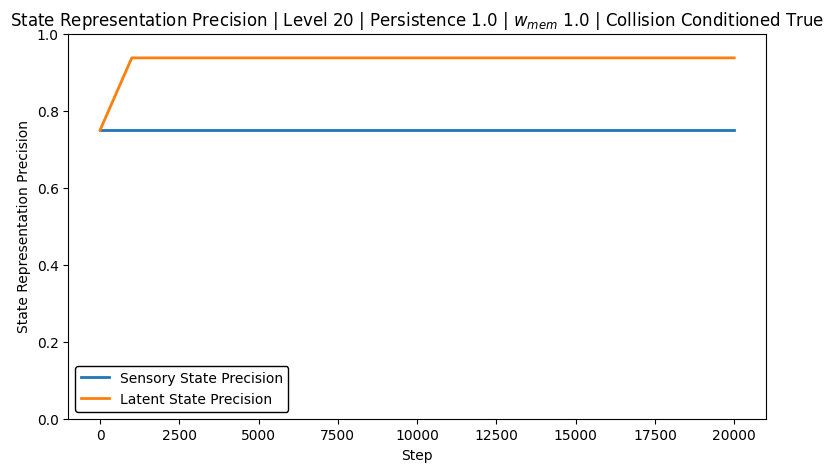

State Representation Precision | Level 20 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/state_representation_precision_level_20_persistence_1_0_w_mem_1_0_collision_conditioned_false.png


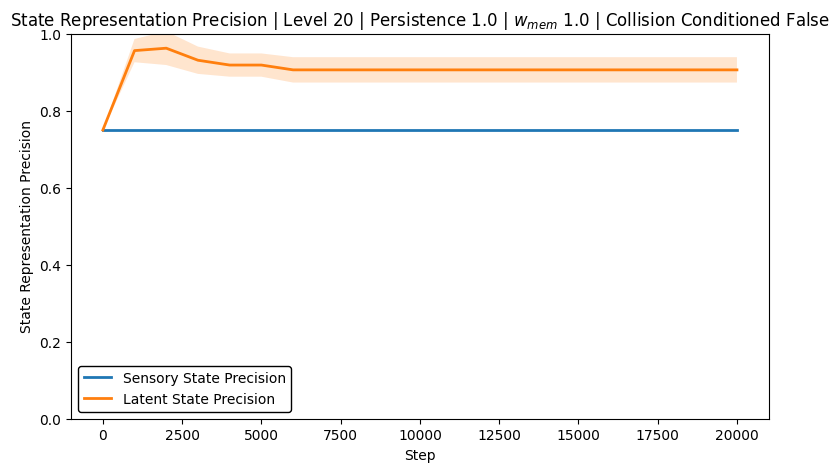

State Representation Precision | Level 20 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/state_representation_precision_level_20_persistence_0_7_w_mem_1_0_collision_conditioned_true.png


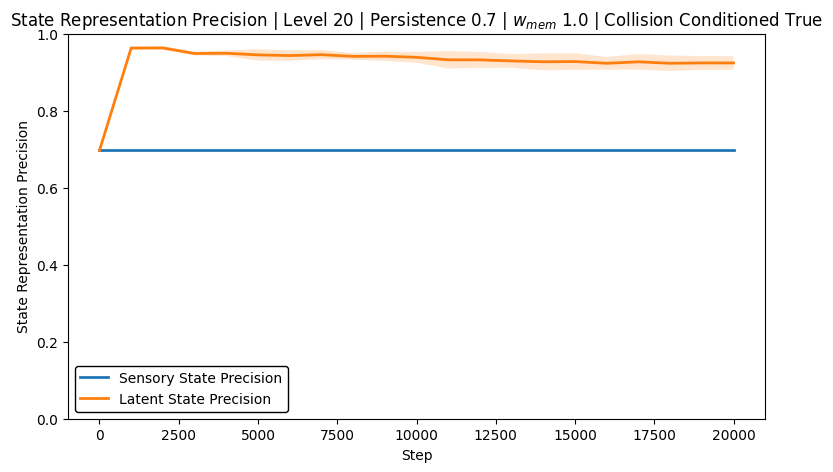

State Representation Precision | Level 20 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/state_representation_precision_level_20_persistence_0_7_w_mem_1_0_collision_conditioned_false.png


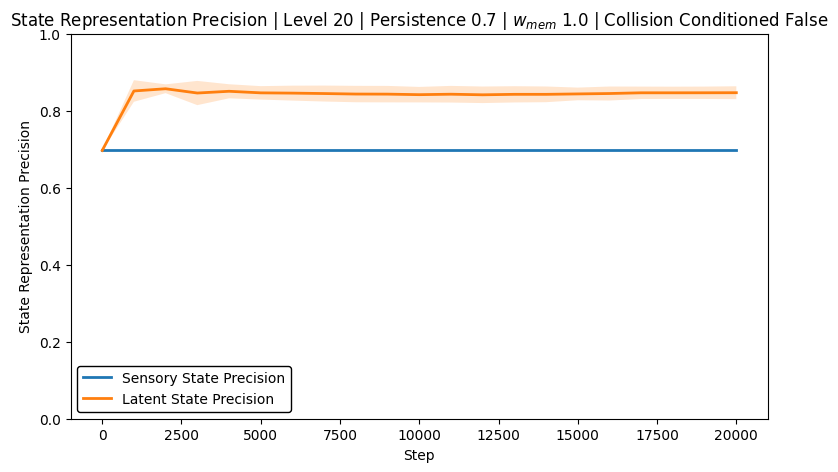

State Representation Precision | Level 21 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/state_representation_precision_level_21_persistence_1_0_w_mem_0_8_collision_conditioned_true.png


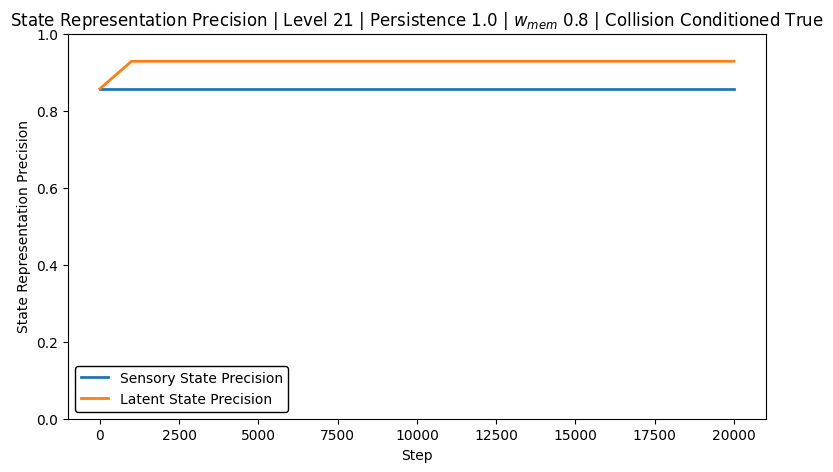

State Representation Precision | Level 21 | Persistence 1.0 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/state_representation_precision_level_21_persistence_1_0_w_mem_0_8_collision_conditioned_false.png


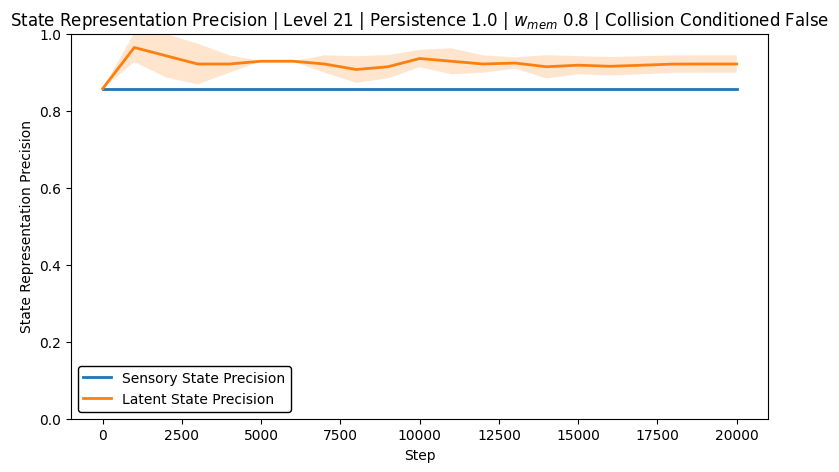

State Representation Precision | Level 21 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned True
Saved plot: results/current/notebook_plots/state_representation_precision_level_21_persistence_0_7_w_mem_0_8_collision_conditioned_true.png


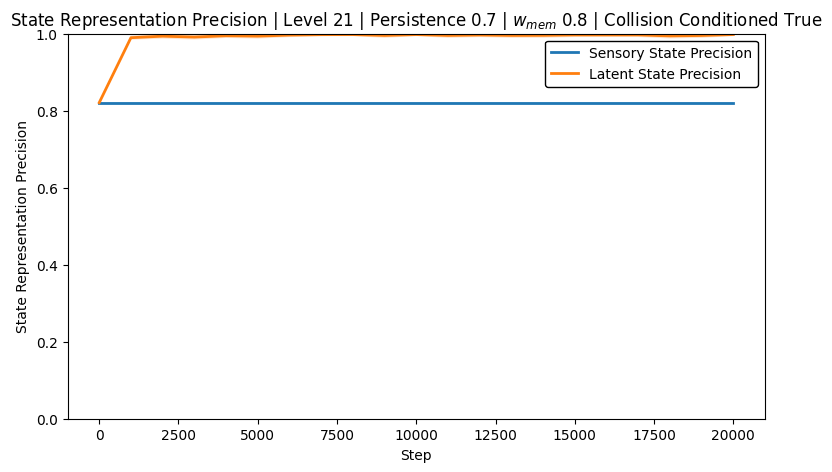

State Representation Precision | Level 21 | Persistence 0.7 | $w_{mem}$ 0.8 | Collision Conditioned False
Saved plot: results/current/notebook_plots/state_representation_precision_level_21_persistence_0_7_w_mem_0_8_collision_conditioned_false.png


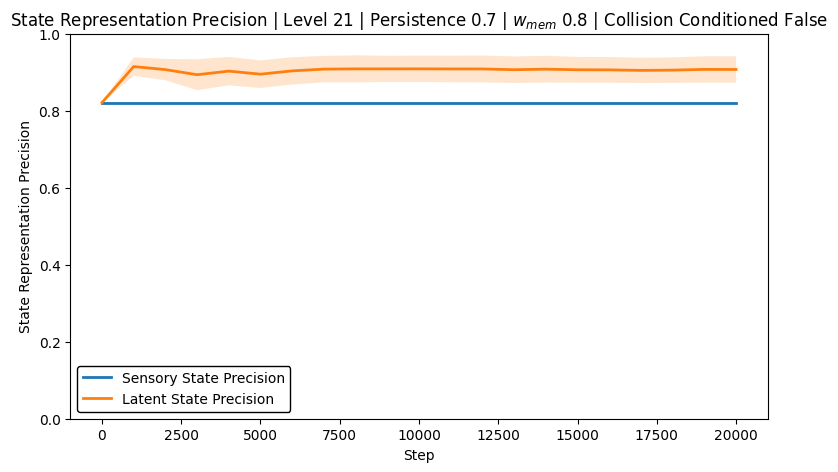

State Representation Precision | Level 21 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/state_representation_precision_level_21_persistence_1_0_w_mem_1_0_collision_conditioned_true.png


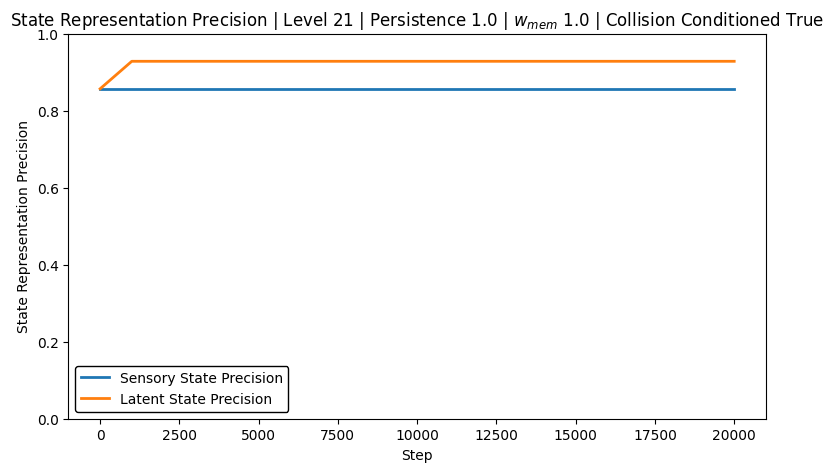

State Representation Precision | Level 21 | Persistence 1.0 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/state_representation_precision_level_21_persistence_1_0_w_mem_1_0_collision_conditioned_false.png


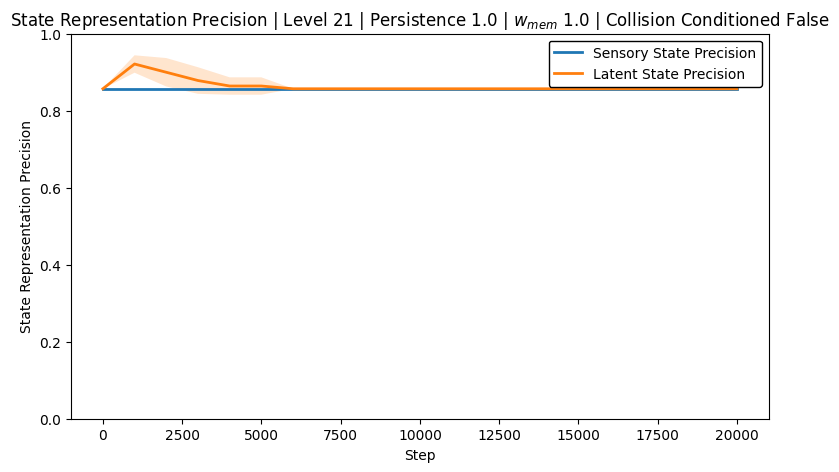

State Representation Precision | Level 21 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned True
Saved plot: results/current/notebook_plots/state_representation_precision_level_21_persistence_0_7_w_mem_1_0_collision_conditioned_true.png


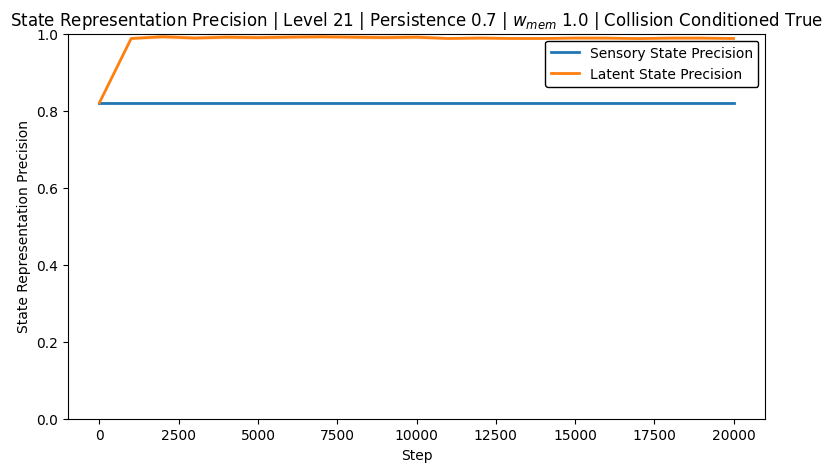

State Representation Precision | Level 21 | Persistence 0.7 | $w_{mem}$ 1.0 | Collision Conditioned False
Saved plot: results/current/notebook_plots/state_representation_precision_level_21_persistence_0_7_w_mem_1_0_collision_conditioned_false.png


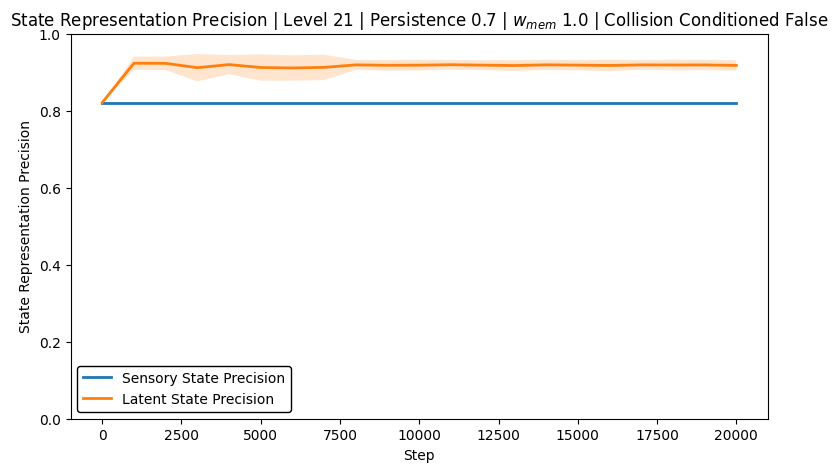

In [15]:
levels = [13,20,21]
weights_mem = [0.8, 1.0]
rand_probs = [0.0, 0.3]
valid_onlys = [True, False]
for level in levels:
    for weight_mem in weights_mem:
        for rand_prob in rand_probs:
            for valid_only in valid_onlys:
                level_comparison_plot = plotting.NotebookPlot(
                        shared_filters={
                            "rand_prob": rand_prob,
                            "weight_memory": weight_mem,
                            "mercury_split_sensory_raw_latent_valid": valid_only,
                            "level": level,
                        },
                        title_spec=plotting.NotebookTitleSpec(
                            metric_label_mode="custom",
                            metric_label_text="State Representation Precision",
                            separator=" | ",
                            parameter_specs=[
                                plotting.build_title_parameter_spec(
                                    plotting.CANONICAL_TITLE_PARAMETERS[parameter_name]
                                )
                                for parameter_name in plotting.CANONICAL_TITLE_PARAMETER_ORDER
                            ],
                        ),
                        series=[
                           plotting.NotebookSeries(
                                name="sensory_edge_F1",
                                metric_column_name="sensory_precision",
                                label="Sensory State Precision",
                                band_alpha=0.20,
                                show_standard_deviation_band=True,
                            ),
                            plotting.NotebookSeries(
                                name="latent mean_total_variation",
                                metric_column_name="latent_precision",
                                label="Latent State Precision",
                                band_alpha=0.20,
                                show_standard_deviation_band=True,
                            ),



                        ],
                        y_axis_label="State Representation Precision",
                        y_limits=(0.0, 1.0),
                        use_grid=False,
                    )
                print(plotting.generate_notebook_plot_title(level_comparison_plot))

                plotting.display_notebook_plot(results, level_comparison_plot)

shape: (5, 8)
┌─────────────┬───────┬───────────┬────────────┬────────────┬────────────┬────────────┬────────────┐
│ run_id      ┆ level ┆ rand_prob ┆ weight_mem ┆ mercury_sp ┆ mercury_pa ┆ mercury_st ┆ mercury_la │
│ ---         ┆ ---   ┆ ---       ┆ ory        ┆ lit_sensor ┆ per_precis ┆ ates_parqu ┆ tent_graph │
│ str         ┆ i64   ┆ f64       ┆ ---        ┆ y_raw_late ┆ ion_json   ┆ et         ┆ _npz       │
│             ┆       ┆           ┆ f64        ┆ …          ┆ ---        ┆ ---        ┆ ---        │
│             ┆       ┆           ┆            ┆ ---        ┆ str        ┆ str        ┆ str        │
│             ┆       ┆           ┆            ┆ bool       ┆            ┆            ┆            │
╞═════════════╪═══════╪═══════════╪════════════╪════════════╪════════════╪════════════╪════════════╡
│ 15a3f3d0420 ┆ 20    ┆ 0.3       ┆ 1.0        ┆ true       ┆ /Users/lca ┆ /Users/lca ┆ /Users/lca │
│ 9           ┆       ┆           ┆            ┆            ┆ rv/Pycharm ┆ rv

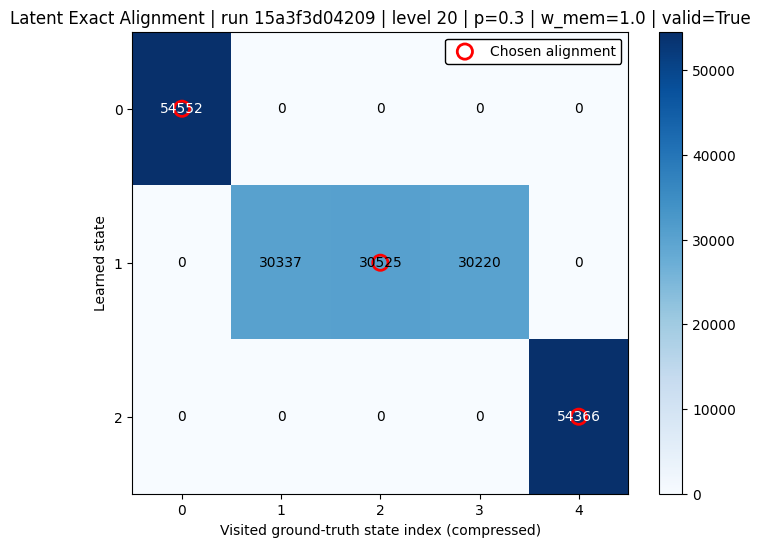

Saved plot: results/current/notebook_plots/latent_exact_alignment_run_15a3f3d04209_level_20_p_0_3_w_mem_1_0_valid_true.png


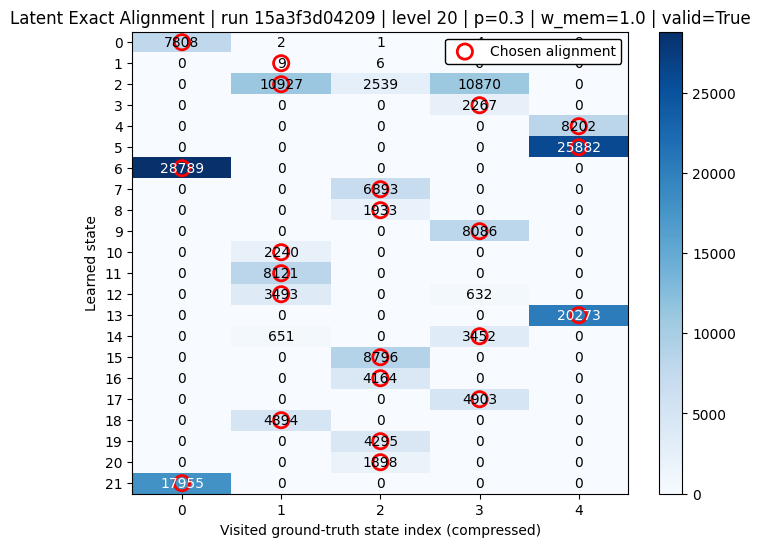

{'run_id': '15a3f3d04209', 'level': 20, 'rand_prob': 0.3, 'weight_memory': 1.0, 'mercury_split_sensory_raw_latent_valid': True, 'mercury_paper_precision_json': '/Users/lcarv/PycharmProjects/mercuryv5/results/current/studies/levels_13_21_22_memory_study_fixed_eval_1/15a3f3d04209/metrics/mercury/15a3f3d04209_paper_precision.json', 'mercury_states_parquet': '/Users/lcarv/PycharmProjects/mercuryv5/results/current/studies/levels_13_21_22_memory_study_fixed_eval_1/15a3f3d04209/bundles/mercury/level=20/sensor=cardinal distance/range=1/15a3f3d04209_states.parquet', 'mercury_latent_graph_npz': '/Users/lcarv/PycharmProjects/mercuryv5/results/current/studies/levels_13_21_22_memory_study_fixed_eval_1/15a3f3d04209/bundles/mercury/level=20/sensor=cardinal distance/range=1/15a3f3d04209_latent_graph.npz'}
[[ 7808     2     1     4     9]
 [    0     9     6     6     0]
 [    0 10927  2539 10870     0]
 [    0     0     0  2267     0]
 [    0     0     0     0  8202]
 [    0     0     0     0 25882]
 

In [16]:
alignment_level = 20
alignment_rand_prob = 0.3
alignment_weight_memory = 1.0
alignment_valid_only = True

alignment_candidates = dataset.runs.filter(
    (pl.col("level") == alignment_level)
    & (pl.col("rand_prob") == alignment_rand_prob)
    & (pl.col("weight_memory") == alignment_weight_memory)
    & (pl.col("mercury_split_sensory_raw_latent_valid") == alignment_valid_only)
).select([
    "run_id",
    "level",
    "rand_prob",
    "weight_memory",
    "mercury_split_sensory_raw_latent_valid",
    "mercury_paper_precision_json",
    "mercury_states_parquet",
    "mercury_latent_graph_npz",
]).sort("run_id")

if alignment_candidates.is_empty():
    raise ValueError(
        f"No runs found for level={alignment_level}, rand_prob={alignment_rand_prob}, "
        f"weight_memory={alignment_weight_memory}, valid_only={alignment_valid_only}"
    )

alignment_run = alignment_candidates.row(0, named=True)
print(alignment_candidates.head(5))

alignment_demo = plotting.display_alignment_contingency_heatmap_from_paper_precision_json(
    paper_precision_json_path=alignment_run["mercury_paper_precision_json"],
    matrix_key="sensory_exact_state_cooccurrence_matrix",
    title=(
        f"Latent Exact Alignment | run {alignment_run['run_id']} | "
        f"level {alignment_run['level']} | p={alignment_run['rand_prob']} | "
        f"w_mem={alignment_run['weight_memory']} | valid={alignment_run['mercury_split_sensory_raw_latent_valid']}"
    ),
)
alignment_demo = plotting.display_alignment_contingency_heatmap_from_paper_precision_json(
    paper_precision_json_path=alignment_run["mercury_paper_precision_json"],
    matrix_key="latent_exact_state_cooccurrence_matrix",
    title=(
        f"Latent Exact Alignment | run {alignment_run['run_id']} | "
        f"level {alignment_run['level']} | p={alignment_run['rand_prob']} | "
        f"w_mem={alignment_run['weight_memory']} | valid={alignment_run['mercury_split_sensory_raw_latent_valid']}"
    ),
)

print(alignment_run)
print(alignment_demo.contingency)
print(alignment_demo.alignment)


Saved plot: results/current/notebook_plots/latent_exact_masked_alignment_over_time_compressed_gt_axis_run_15a3f3d04209_level_20_history.png


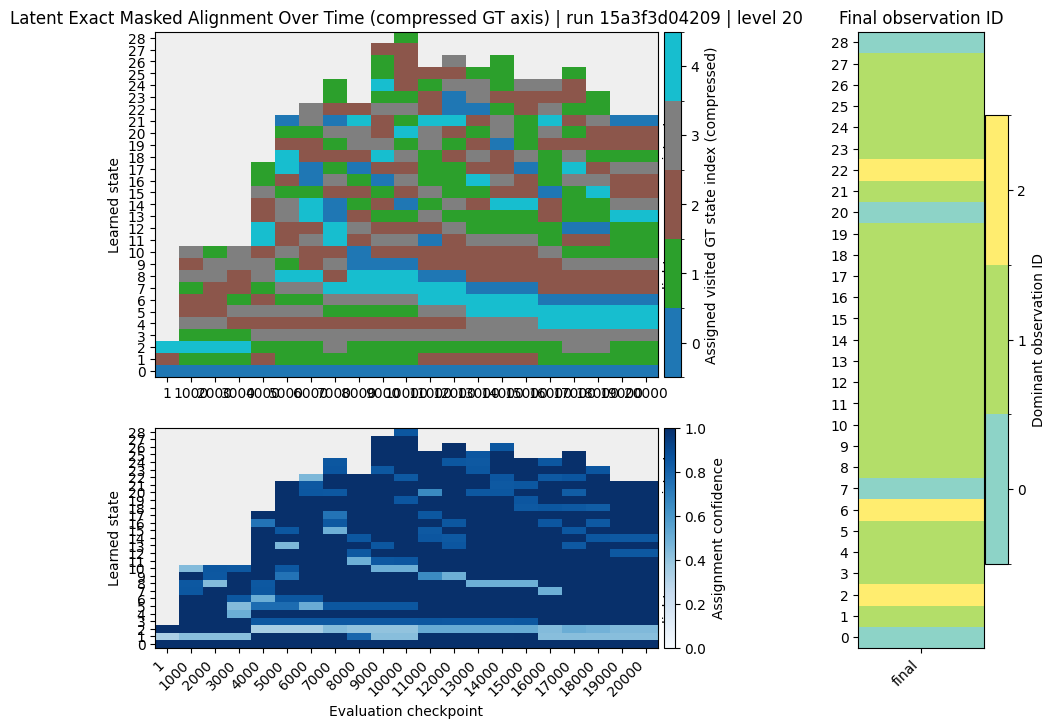

steps [1, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, 10000, 11000, 12000, 13000, 14000, 15000, 16000, 17000, 18000, 19000, 20000]
assignments_shape (21, 29)
confidence_shape (21, 29)
active_mask_shape (21, 29)


In [17]:
alignment_history_demo = plotting.display_alignment_history_from_paper_precision_json(
    paper_precision_json_path=alignment_run["mercury_paper_precision_json"],
    states_parquet_path=alignment_run["mercury_states_parquet"],
    matrix_key="latent_exact_state_cooccurrence_matrix",
    title=(
        f"Latent Exact Masked Alignment Over Time (compressed GT axis) | run {alignment_run['run_id']} | "
        f"level {alignment_run['level']}"
    ),
)

print('steps', alignment_history_demo.steps.tolist())
print('assignments_shape', alignment_history_demo.assignments.shape)
print('confidence_shape', alignment_history_demo.confidence.shape)
print('active_mask_shape', alignment_history_demo.active_mask.shape)


/Users/lcarv/PycharmProjects/mercuryv5/scripts/analysis
Saved figure to /Users/lcarv/PycharmProjects/mercuryv5/scripts/analysis/results/figures/Sensory_vs_Latent_$TV_{mean}$.png


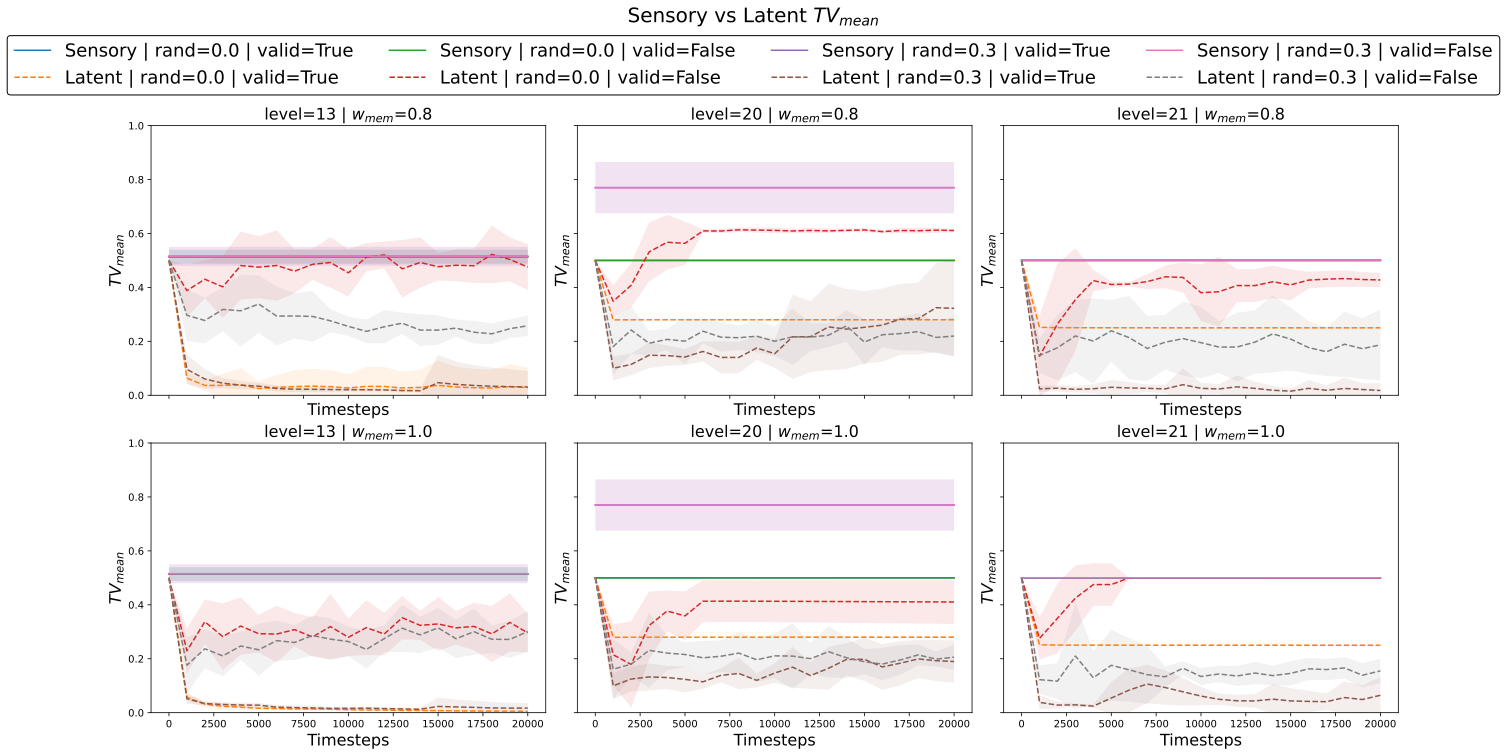

Saved figure to /Users/lcarv/PycharmProjects/mercuryv5/scripts/analysis/results/figures/Sensory_vs_Latent_$TV^{act}_{mean}$.png


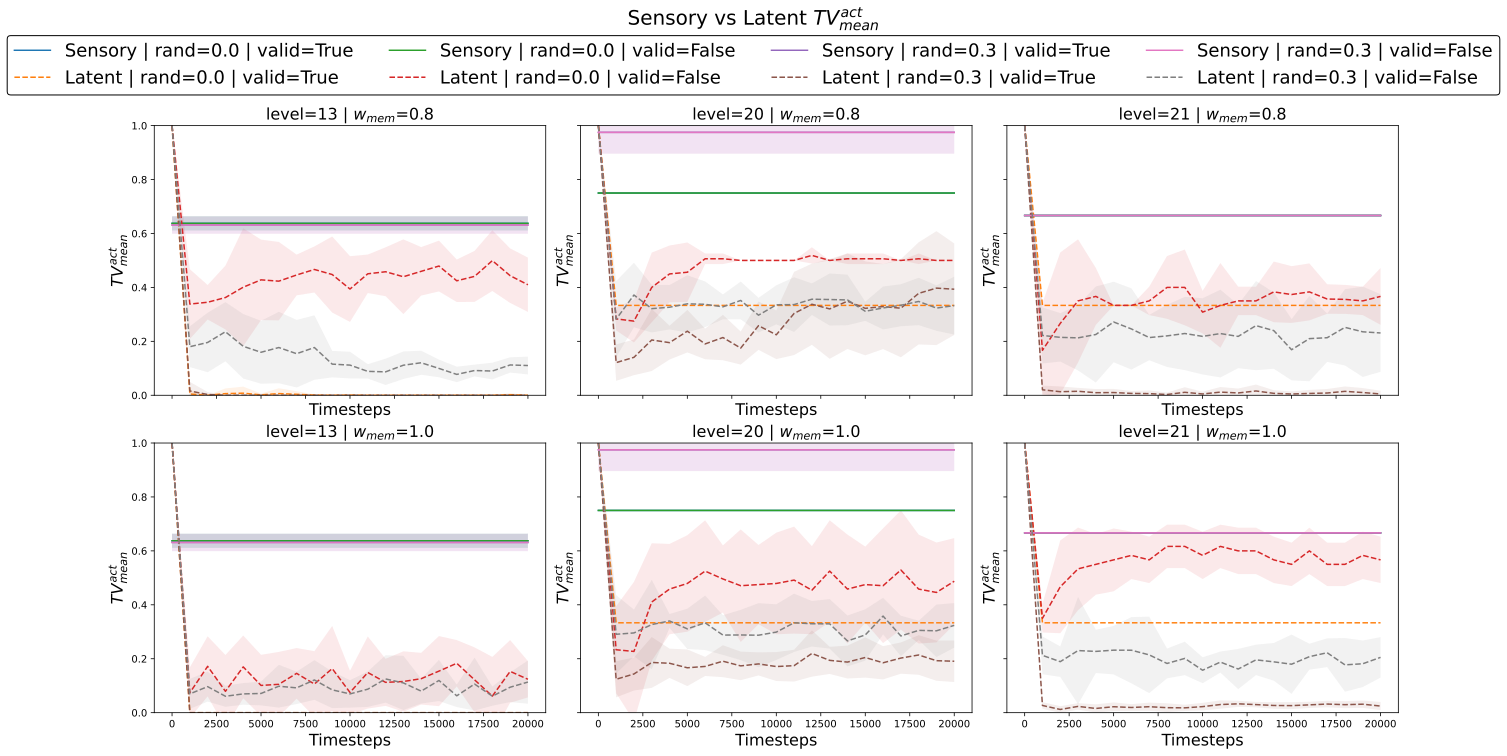

Saved figure to /Users/lcarv/PycharmProjects/mercuryv5/scripts/analysis/results/figures/Sensory_vs_Latent_State_Precision.png


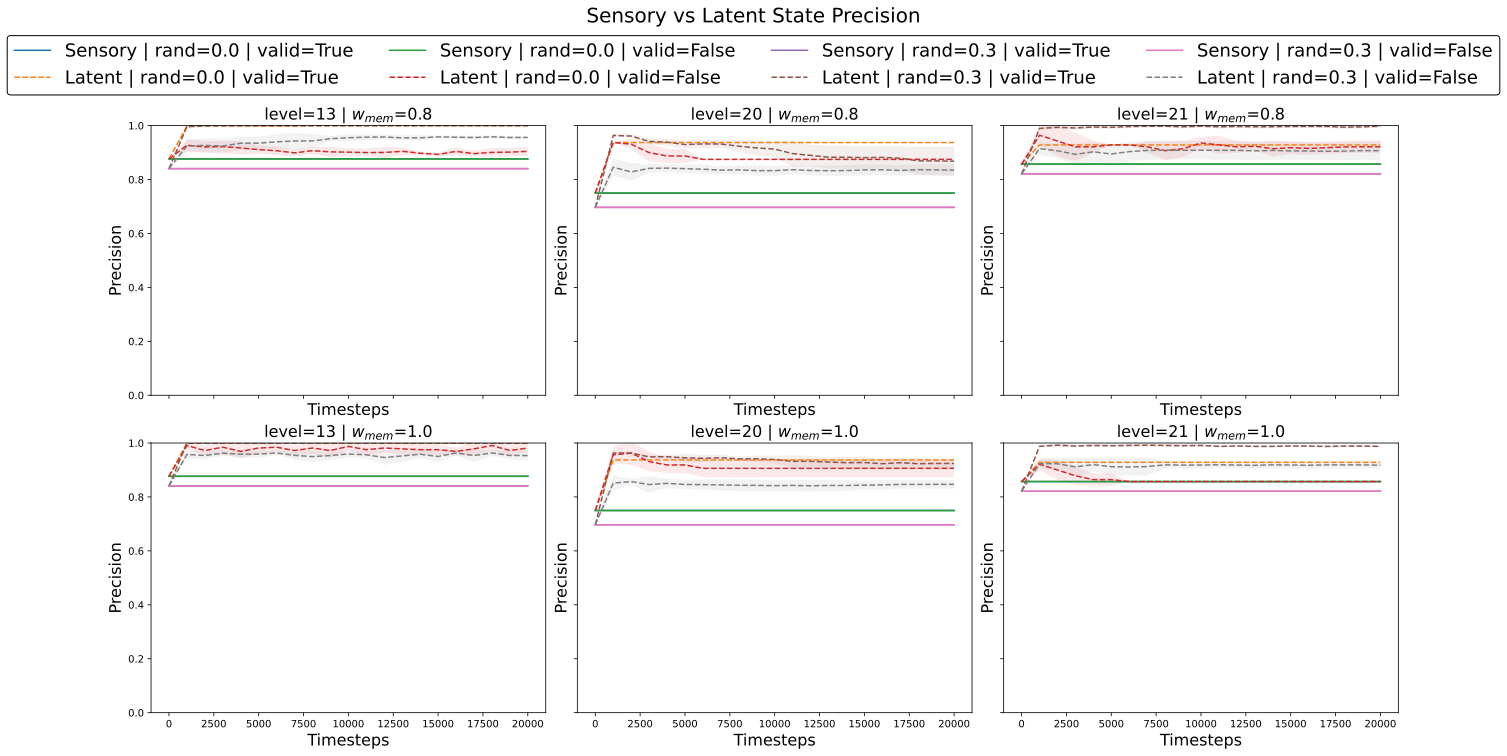

Saved figure to /Users/lcarv/PycharmProjects/mercuryv5/scripts/analysis/results/figures/Sensory_vs_Latent_State_Recall.png


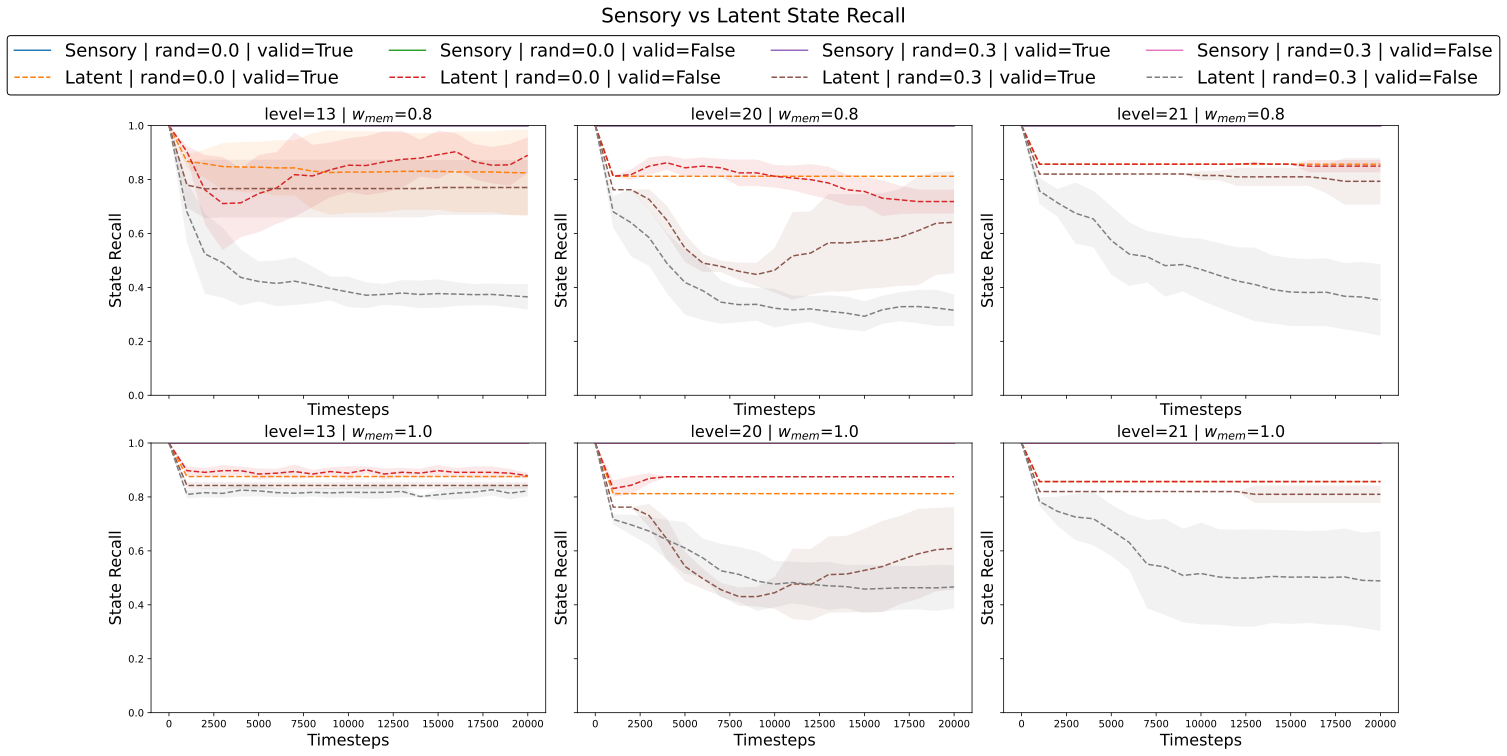

Saved figure to /Users/lcarv/PycharmProjects/mercuryv5/scripts/analysis/results/figures/Sensory_vs_Latent_Edge_F1.png


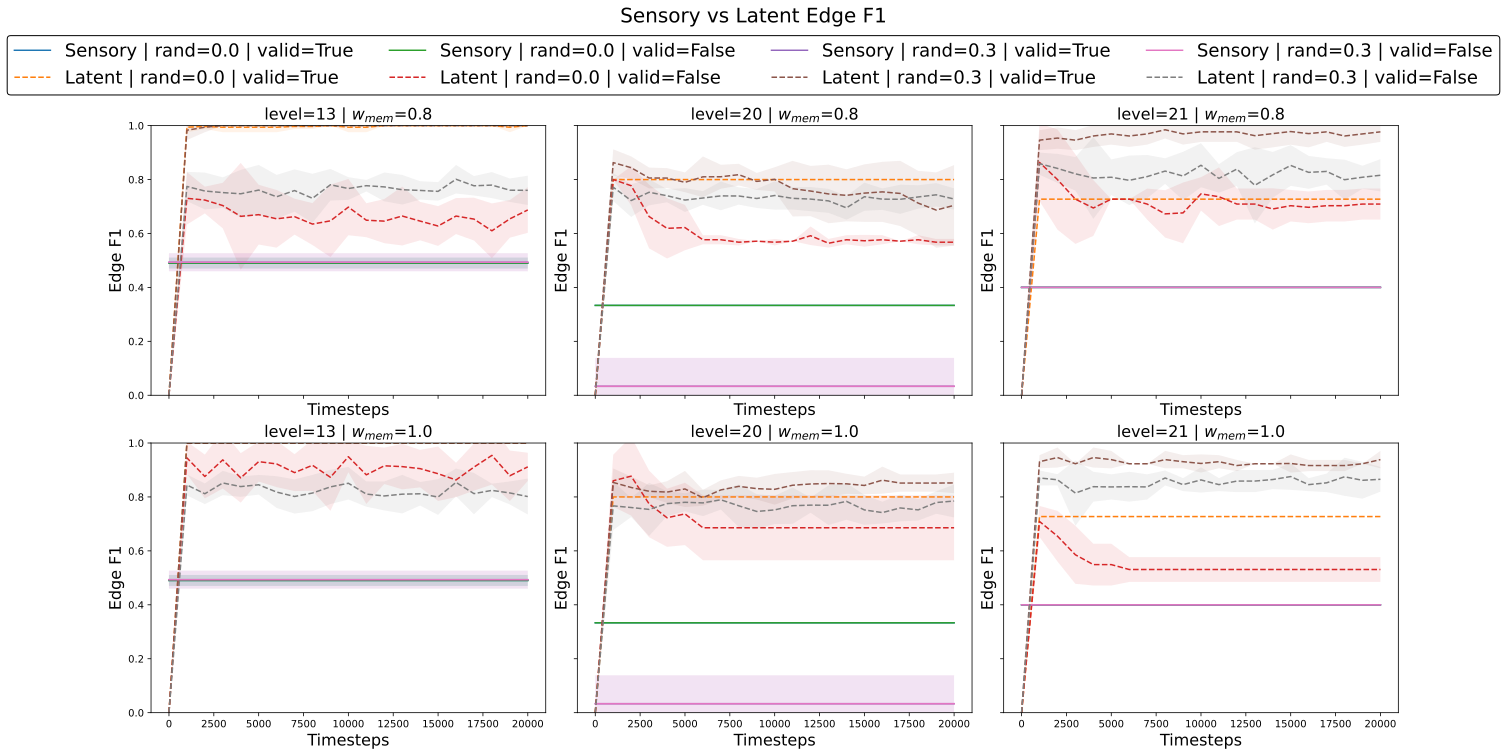

Saved figure to /Users/lcarv/PycharmProjects/mercuryv5/scripts/analysis/results/figures/Sensory_vs_Latent_Edge_Precision.png


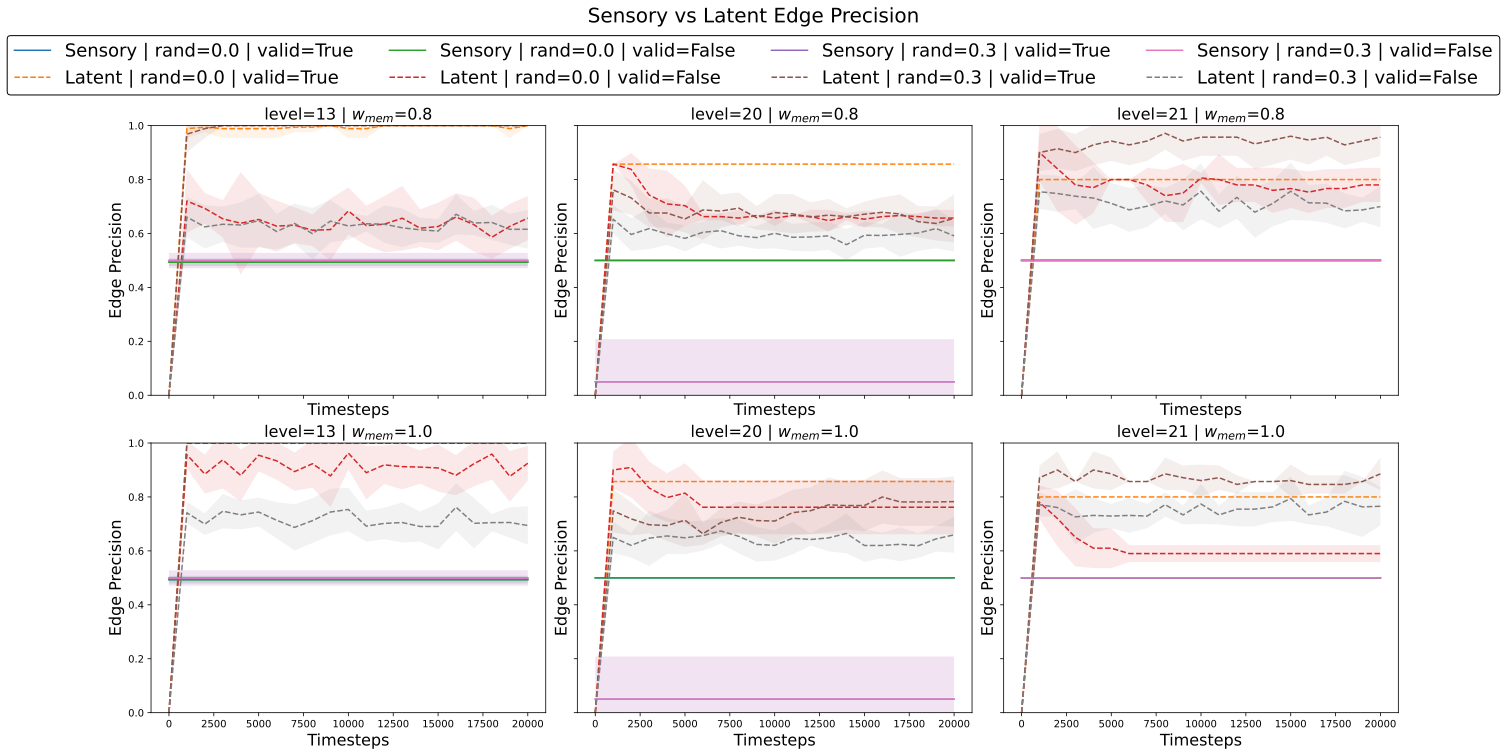

Saved figure to /Users/lcarv/PycharmProjects/mercuryv5/scripts/analysis/results/figures/Sensory_vs_Latent_Edge_Recall.png


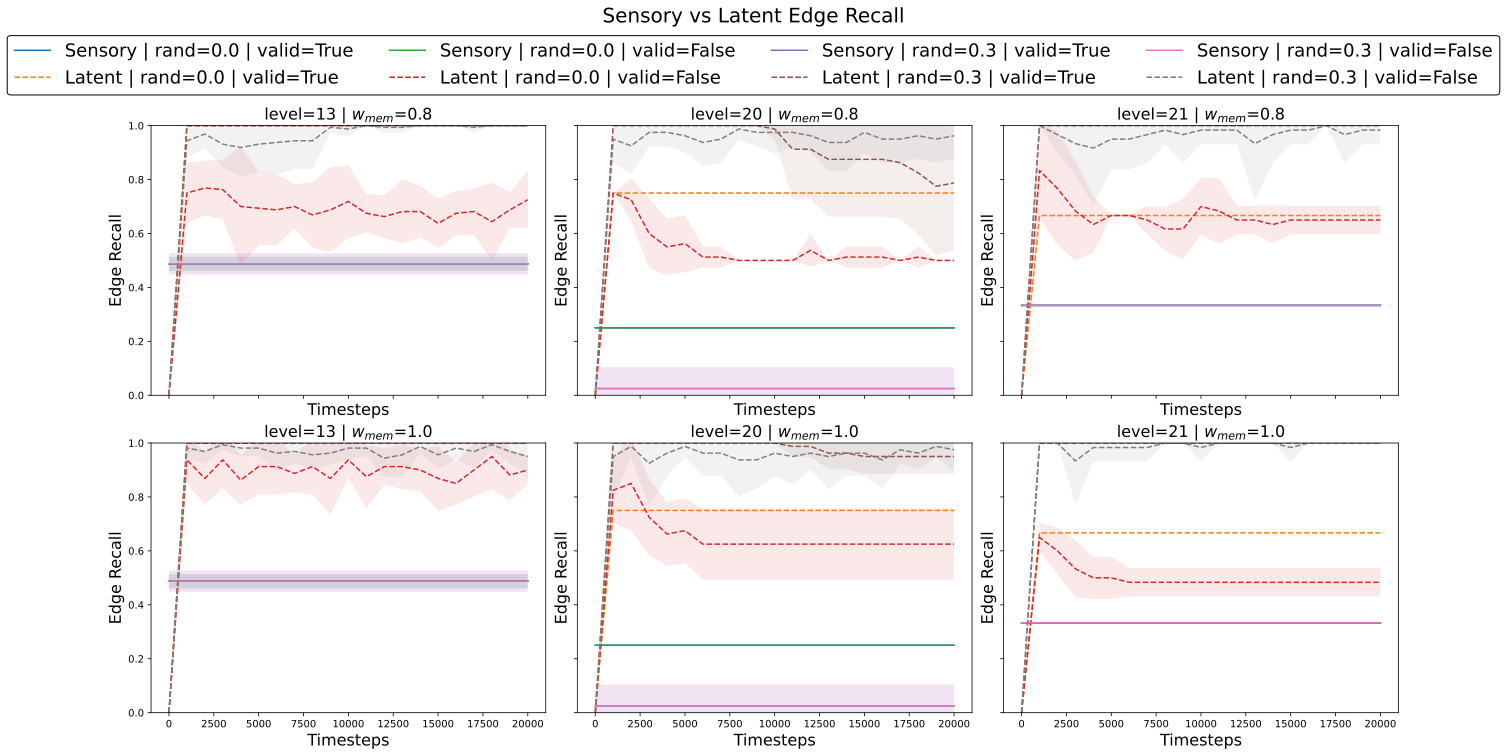

Saved figure to /Users/lcarv/PycharmProjects/mercuryv5/scripts/analysis/results/figures/Sensory_vs_Latent_Action-Conditioned_Edge_F1.png


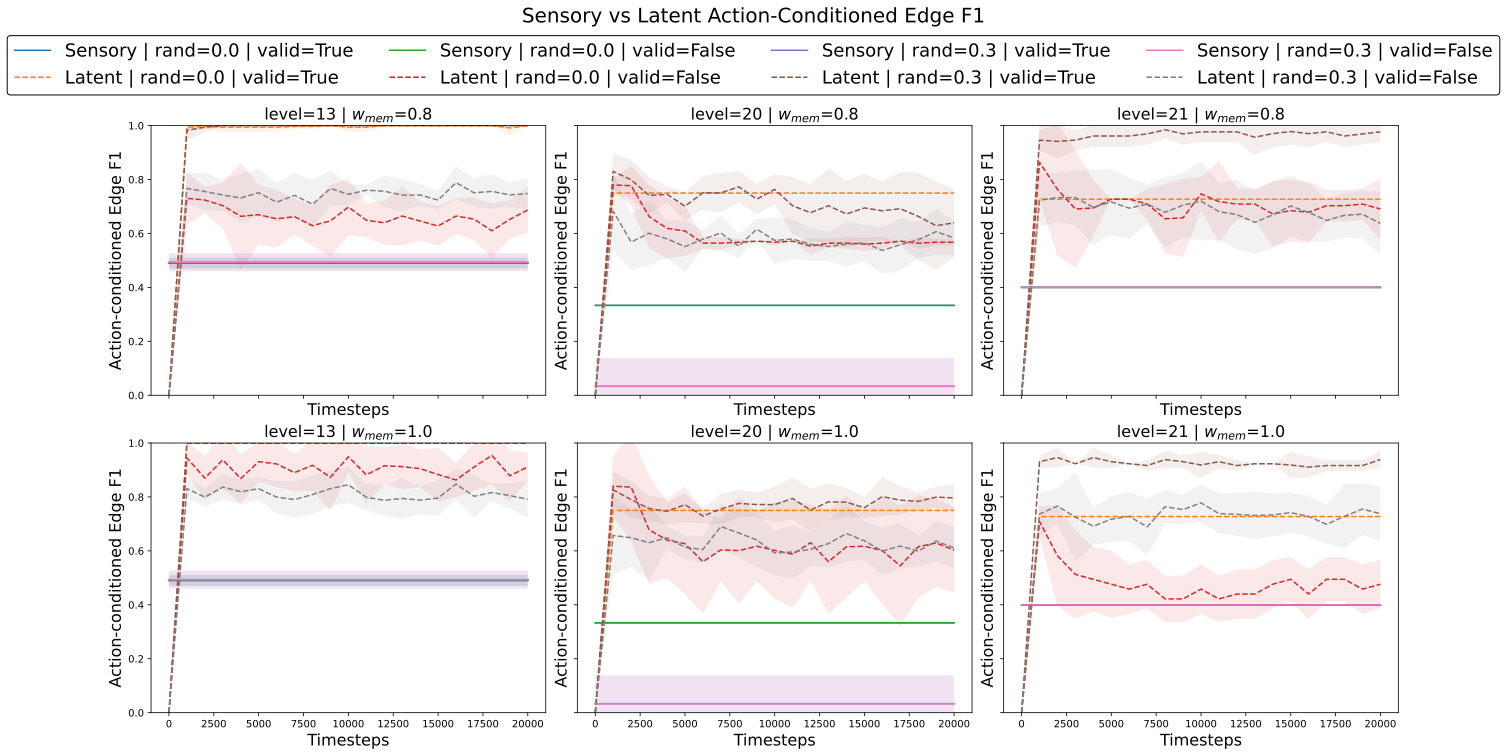

Saved figure to /Users/lcarv/PycharmProjects/mercuryv5/scripts/analysis/results/figures/Sensory_vs_Latent_Action-Conditioned_Edge_Precision.png


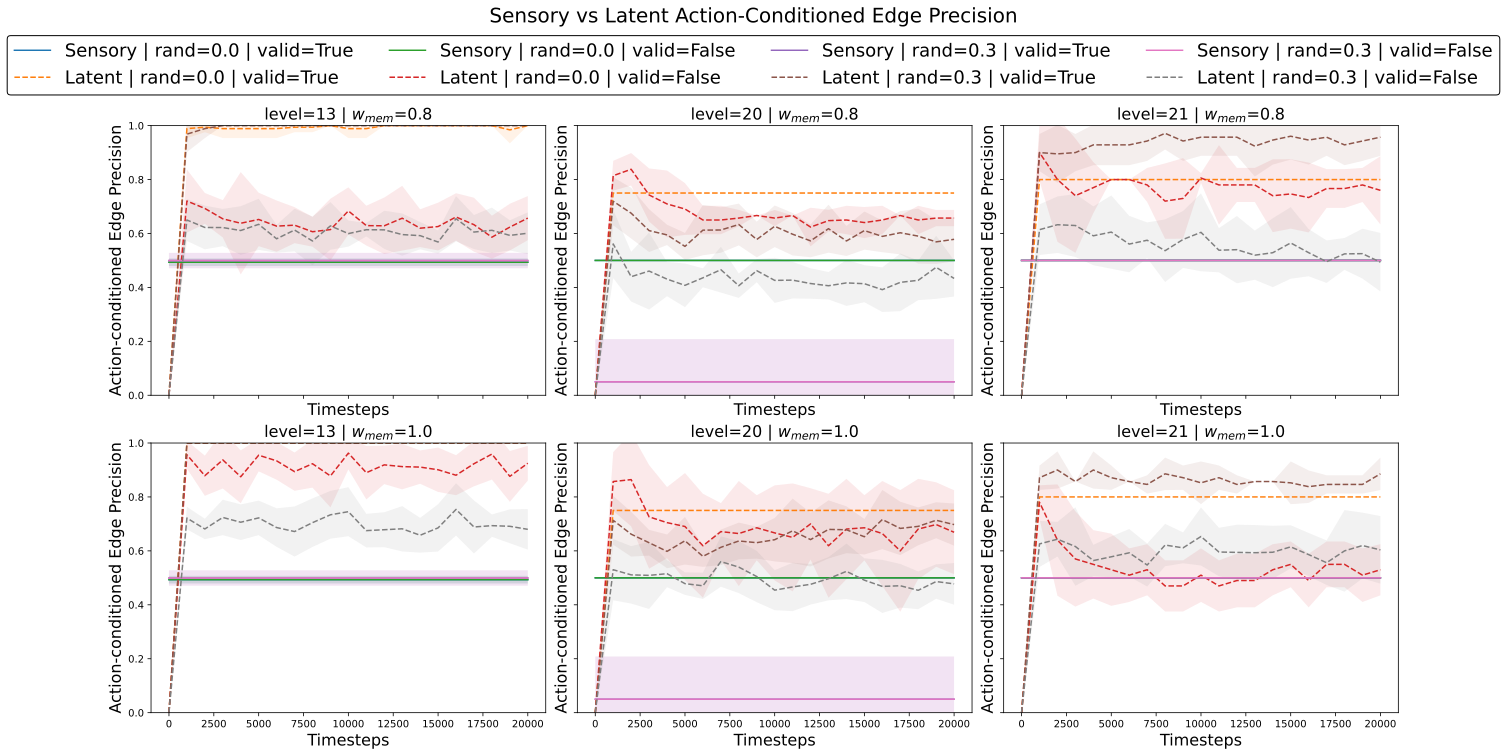

Saved figure to /Users/lcarv/PycharmProjects/mercuryv5/scripts/analysis/results/figures/Sensory_vs_Latent_Action-Conditioned_Edge_Recall.png


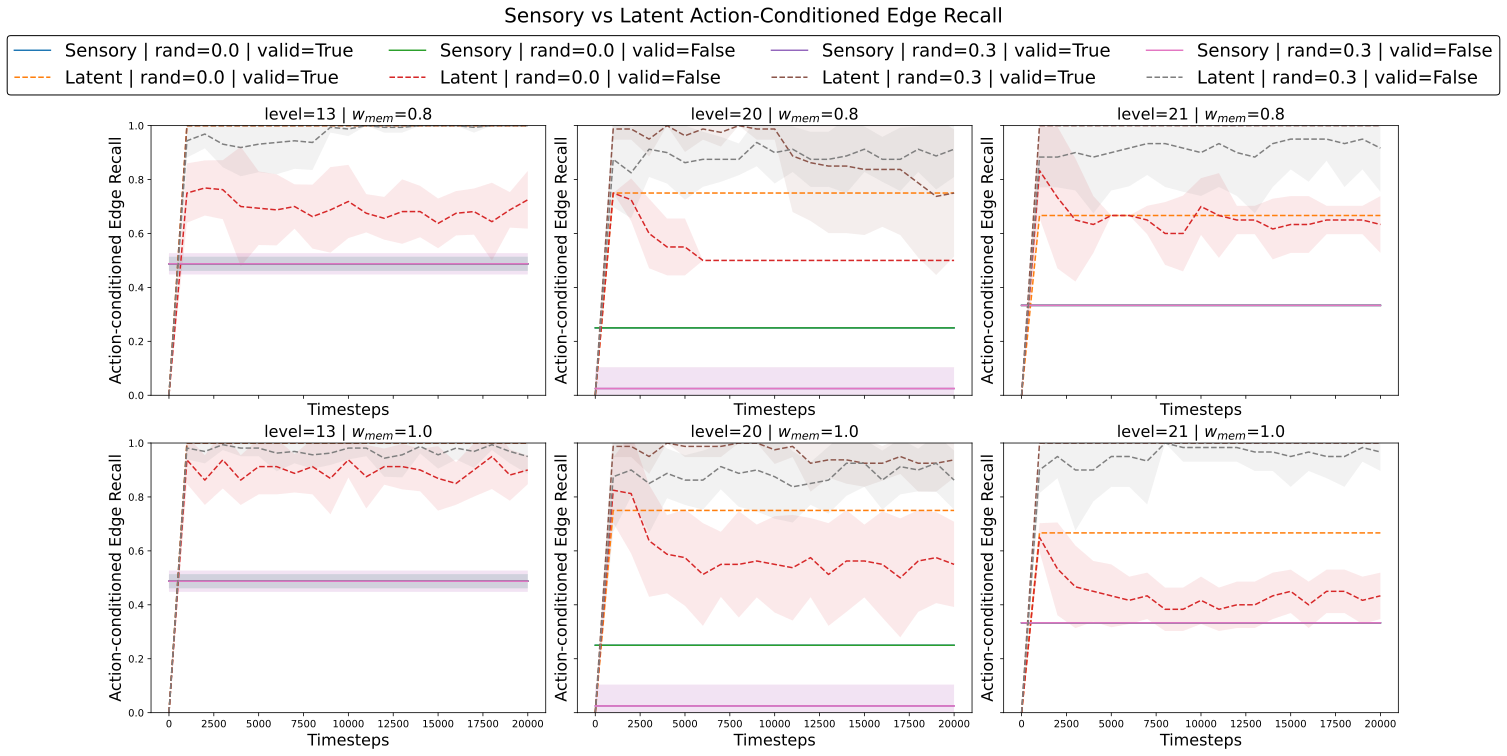

In [20]:
import matplotlib.pyplot as plt
import polars as pl
from pathlib import Path
print(Path.cwd())

levels = [13, 20, 21]
memory_weights = [0.8, 1.0]
random_action_probabilities = [0.0, 0.3]
valid_only_options = [True, False]

condition_label_map = {
    (0.0, False): "rand=0.0 | valid=False",
    (0.0, True): "rand=0.0 | valid=True",
    (0.3, False): "rand=0.3 | valid=False",
    (0.3, True): "rand=0.3 | valid=True",
}


def build_joined_step_metrics_dataframe(
    study_dataset: pl.DataFrame,
    step_metrics: pl.DataFrame,
) -> pl.DataFrame:
    """
    Join config metadata onto per-step metrics through run_id.
    """
    metadata_columns = [
        "run_id",
        "level",
        "rand_prob",
        "weight_memory",
        "mercury_split_sensory_raw_latent_valid",
        "seed",
    ]

    metadata = study_dataset.select(metadata_columns).unique()

    joined = step_metrics.join(
        metadata,
        on="run_id",
        how="inner",
    )

    return joined


def aggregate_metric_over_seeds(
    joined_step_metrics: pl.DataFrame,
    metric_column_name: str,
) -> pl.DataFrame:
    """
    Compute mean and std across seeds for each condition at each step.
    """
    aggregated = (
        joined_step_metrics
        .group_by(
            [
                "level",
                "weight_memory",
                "rand_prob",
                "mercury_split_sensory_raw_latent_valid",
                "step",
            ]
        )
        .agg(
            [
                pl.col(metric_column_name).mean().alias("metric_mean"),
                pl.col(metric_column_name).std().fill_null(0.0).alias("metric_std"),
            ]
        )
        .sort(
            [
                "level",
                "weight_memory",
                "rand_prob",
                "mercury_split_sensory_raw_latent_valid",
                "step",
            ]
        )
    )

    return aggregated


def plot_metric_grid(
    aggregated_sensory_metric: pl.DataFrame,
    aggregated_latent_metric: pl.DataFrame,
    figure_title: str,
    y_axis_label: str,
    y_limits: tuple[float, float] | None = None,
    show_standard_deviation_band: bool = False,
):
    figure, axes = plt.subplots(
        nrows=len(memory_weights),
        ncols=len(levels),
        figsize=(18, 9),
        sharex=True,
        sharey=True,
        constrained_layout=False,
        dpi=200,
    )

    for row_index, memory_weight in enumerate(memory_weights):
        for column_index, level in enumerate(levels):
            axis = axes[row_index, column_index]

            for random_action_probability in random_action_probabilities:
                for valid_only in valid_only_options:
                    sensory_subset = (
                        aggregated_sensory_metric
                        .filter(
                            (pl.col("level") == level)
                            & (pl.col("weight_memory") == memory_weight)
                            & (pl.col("rand_prob") == random_action_probability)
                            & (
                                pl.col("mercury_split_sensory_raw_latent_valid")
                                == valid_only
                            )
                        )
                        .sort("step")
                    )

                    latent_subset = (
                        aggregated_latent_metric
                        .filter(
                            (pl.col("level") == level)
                            & (pl.col("weight_memory") == memory_weight)
                            & (pl.col("rand_prob") == random_action_probability)
                            & (
                                pl.col("mercury_split_sensory_raw_latent_valid")
                                == valid_only
                            )
                        )
                        .sort("step")
                    )

                    if sensory_subset.height == 0 or latent_subset.height == 0:
                        continue

                    condition_label = condition_label_map[
                        (random_action_probability, valid_only)
                    ]

                    sensory_steps = sensory_subset["step"].to_list()
                    sensory_means = sensory_subset["metric_mean"].to_list()
                    sensory_stds = sensory_subset["metric_std"].to_list()

                    latent_steps = latent_subset["step"].to_list()
                    latent_means = latent_subset["metric_mean"].to_list()
                    latent_stds = latent_subset["metric_std"].to_list()

                    sensory_line = axis.plot(
                        sensory_steps,
                        sensory_means,
                        linestyle="-",
                        label=f"Sensory | {condition_label}",
                    )[0]

                    latent_line = axis.plot(
                        latent_steps,
                        latent_means,
                        linestyle="--",
                        label=f"Latent | {condition_label}",
                    )[0]

                    if show_standard_deviation_band:
                        axis.fill_between(
                            sensory_steps,
                            [mean - std for mean, std in zip(sensory_means, sensory_stds)],
                            [mean + std for mean, std in zip(sensory_means, sensory_stds)],
                            alpha=0.10,
                        )
                        axis.fill_between(
                            latent_steps,
                            [mean - std for mean, std in zip(latent_means, latent_stds)],
                            [mean + std for mean, std in zip(latent_means, latent_stds)],
                            alpha=0.10,
                        )

            axis.set_title(f"level={level} | $w_{{mem}}$={memory_weight}", fontsize=16)
            axis.set_xlabel("Timesteps", fontsize=16)
            axis.set_ylabel(y_axis_label, fontsize=16)

            if y_limits is not None:
                axis.set_ylim(*y_limits)

            axis.grid(False)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(
        handles,
        labels,
        fontsize=18,
        loc="upper center",
        ncol=4,
        bbox_to_anchor=(0.5, 1.12),
    )
    figure.suptitle(figure_title, y=1.15, fontsize=20)



    output_directory = Path(Path.cwd() / "results") / "figures"
    output_directory.mkdir(parents=True, exist_ok=True)

    output_filename = figure_title.replace(" ", "_")
    output_path = output_directory / f"{output_filename}.png"

    figure.savefig(output_path, bbox_inches="tight")
    print(f"Saved figure to {output_path}")
    plt.show()


joined_step_metrics = build_joined_step_metrics_dataframe(
    study_dataset=dataset.runs,
    step_metrics=history_with_state_recall,
)

def plot_metric_pair(
    sensory_metric_column_name: str,
    latent_metric_column_name: str,
    figure_title: str,
    y_axis_label: str,
    y_limits: tuple[float, float] | None = (0.0, 1.0),
) -> None:
    aggregated_sensory_metric = aggregate_metric_over_seeds(
        joined_step_metrics=joined_step_metrics,
        metric_column_name=sensory_metric_column_name,
    )
    aggregated_latent_metric = aggregate_metric_over_seeds(
        joined_step_metrics=joined_step_metrics,
        metric_column_name=latent_metric_column_name,
    )
    plot_metric_grid(
        aggregated_sensory_metric=aggregated_sensory_metric,
        aggregated_latent_metric=aggregated_latent_metric,
        figure_title=figure_title,
        y_axis_label=y_axis_label,
        y_limits=y_limits,
        show_standard_deviation_band=True,
    )


plot_metric_pair(
    sensory_metric_column_name="sensory_mean_total_variation",
    latent_metric_column_name="latent_mean_total_variation",
    figure_title="Sensory vs Latent $TV_{mean}$",
    y_axis_label=r"$TV_{mean}$",
)

plot_metric_pair(
    sensory_metric_column_name="sensory_action_conditioned_mean_total_variation",
    latent_metric_column_name="latent_action_conditioned_mean_total_variation",
    figure_title="Sensory vs Latent $TV^{act}_{mean}$",
    y_axis_label="$TV^{act}_{mean}$",
)

plot_metric_pair(
    sensory_metric_column_name="sensory_precision",
    latent_metric_column_name="latent_precision",
    figure_title="Sensory vs Latent State Precision",
    y_axis_label="Precision",
)

plot_metric_pair(
    sensory_metric_column_name="sensory_state_recall",
    latent_metric_column_name="latent_state_recall",
    figure_title="Sensory vs Latent State Recall",
    y_axis_label="State Recall",
)

plot_metric_pair(
    sensory_metric_column_name="sensory_edge_f1",
    latent_metric_column_name="latent_edge_f1",
    figure_title="Sensory vs Latent Edge F1",
    y_axis_label="Edge F1",
)

plot_metric_pair(
    sensory_metric_column_name="sensory_edge_precision",
    latent_metric_column_name="latent_edge_precision",
    figure_title="Sensory vs Latent Edge Precision",
    y_axis_label="Edge Precision",
)

plot_metric_pair(
    sensory_metric_column_name="sensory_edge_recall",
    latent_metric_column_name="latent_edge_recall",
    figure_title="Sensory vs Latent Edge Recall",
    y_axis_label="Edge Recall",
)

plot_metric_pair(
    sensory_metric_column_name="sensory_action_conditioned_edge_f1",
    latent_metric_column_name="latent_action_conditioned_edge_f1",
    figure_title="Sensory vs Latent Action-Conditioned Edge F1",
    y_axis_label="Action-conditioned Edge F1",
)

plot_metric_pair(
    sensory_metric_column_name="sensory_action_conditioned_edge_precision",
    latent_metric_column_name="latent_action_conditioned_edge_precision",
    figure_title="Sensory vs Latent Action-Conditioned Edge Precision",
    y_axis_label="Action-conditioned Edge Precision",
)

plot_metric_pair(
    sensory_metric_column_name="sensory_action_conditioned_edge_recall",
    latent_metric_column_name="latent_action_conditioned_edge_recall",
    figure_title="Sensory vs Latent Action-Conditioned Edge Recall",
    y_axis_label="Action-conditioned Edge Recall",
)

In [ ]:
# Final metric reporting: absolute context plus regime-organised deltas.
# TMGWR is the sensory baseline; MERCURY is the latent representation.
# TMGWR is policy-only here, so it is shown once per level/rand while MERCURY is split by valid-only setting and memory weight.

from pathlib import Path
from IPython.display import Markdown, display

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

METHOD_LABELS = {
    "tmgwr": "TMGWR",
    "mercury": "MERCURY",
}

FIGURE_METRICS = [
    {"label": "State precision", "slug": "state_precision", "tmgwr_column": "sensory_precision", "mercury_column": "latent_precision", "lower_is_better": False},
    {"label": "State recall", "slug": "state_recall", "tmgwr_column": "sensory_state_recall", "mercury_column": "latent_state_recall", "lower_is_better": False},
    {"label": "Mean total variation", "slug": "mean_total_variation", "tmgwr_column": "sensory_mean_total_variation", "mercury_column": "latent_mean_total_variation", "lower_is_better": True},
    {"label": "Action-cond. mean TV", "slug": "action_cond_mean_total_variation", "tmgwr_column": "sensory_action_conditioned_mean_total_variation", "mercury_column": "latent_action_conditioned_mean_total_variation", "lower_is_better": True},
    {"label": "Edge precision", "slug": "edge_precision", "tmgwr_column": "sensory_edge_precision", "mercury_column": "latent_edge_precision", "lower_is_better": False},
    {"label": "Edge recall", "slug": "edge_recall", "tmgwr_column": "sensory_edge_recall", "mercury_column": "latent_edge_recall", "lower_is_better": False},
    {"label": "Edge F1", "slug": "edge_f1", "tmgwr_column": "sensory_edge_f1", "mercury_column": "latent_edge_f1", "lower_is_better": False},
    {"label": "Action-cond. edge precision", "slug": "action_cond_edge_precision", "tmgwr_column": "sensory_action_conditioned_edge_precision", "mercury_column": "latent_action_conditioned_edge_precision", "lower_is_better": False},
    {"label": "Action-cond. edge recall", "slug": "action_cond_edge_recall", "tmgwr_column": "sensory_action_conditioned_edge_recall", "mercury_column": "latent_action_conditioned_edge_recall", "lower_is_better": False},
    {"label": "Action-cond. edge F1", "slug": "action_cond_edge_f1", "tmgwr_column": "sensory_action_conditioned_edge_f1", "mercury_column": "latent_action_conditioned_edge_f1", "lower_is_better": False},
]

METADATA_COLUMNS = [
    "level",
    "weight_memory",
    "rand_prob",
    "mercury_split_sensory_raw_latent_valid",
]
PANEL_REGIME_COLUMNS = ["rand_prob"]
BASE_COLUMNS = ["level", *PANEL_REGIME_COLUMNS]
MERCURY_COMBINATIONS = [
    {"valid": False, "weight": 0.8, "key": "raw_w08", "label": "raw w=0.8"},
    {"valid": False, "weight": 1.0, "key": "raw_w10", "label": "raw w=1.0"},
    {"valid": True, "weight": 0.8, "key": "valid_w08", "label": "valid w=0.8"},
    {"valid": True, "weight": 1.0, "key": "valid_w10", "label": "valid w=1.0"},
]

TMGWR_COLOR = "#4E79A7"
MERCURY_COLORS = {
    "raw_w08": "#FDB462",
    "raw_w10": "#F28E2B",
    "valid_w08": "#C2A5CF",
    "valid_w10": "#7B3294",
}
GOOD_BACKGROUND_COLOR = "#2E7D32"
BAD_BACKGROUND_COLOR = "#C62828"
ZERO_COLOR = "#4D4D4D"
EDGE_COLOR = "#262626"
OUTPUT_DIRECTORY = REPO_ROOT / "results" / "current" / "notebook_plots"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)


def _final_step_per_run(history_frame: pl.DataFrame) -> pl.DataFrame:
    final_steps = history_frame.group_by("run_id").agg(pl.col("step").max().alias("step"))
    return history_frame.join(final_steps, on=["run_id", "step"], how="inner")


def _level_label(level: int | float) -> str:
    return f"L{int(level)}"


def _panel_label(row: dict[str, object]) -> str:
    return f"p={float(row['rand_prob']):.1f}"


def _format_stat(mean: float | None, sd: float | None) -> str:
    if mean is None:
        return "NA"
    if sd is None:
        return f"{mean:.3f} ± NA"
    return f"{mean:.3f} ± {sd:.3f}"


def _check_metric_columns(metric: dict[str, object]) -> None:
    missing = [
        column
        for column in [str(metric["tmgwr_column"]), str(metric["mercury_column"]), *METADATA_COLUMNS, "run_id", "seed"]
        if column not in final_metrics_with_metadata.columns
    ]
    if missing:
        raise ValueError(f"Missing columns for {metric['label']}: {missing}")


def _one_mercury_summary(frame: pl.DataFrame, *, combination: dict[str, object], value_column: str, prefix: str) -> pl.DataFrame:
    key = str(combination["key"])
    return (
        frame
        .filter(
            (pl.col("weight_memory") == float(combination["weight"]))
            & (pl.col("mercury_split_sensory_raw_latent_valid") == bool(combination["valid"]))
        )
        .group_by(BASE_COLUMNS)
        .agg([
            pl.len().alias(f"{prefix}_{key}_n"),
            pl.col(value_column).mean().alias(f"{prefix}_{key}_mean"),
            pl.col(value_column).std().fill_null(0.0).alias(f"{prefix}_{key}_sd"),
        ])
    )


def build_absolute_metric_frame(metric: dict[str, object]) -> pl.DataFrame:
    _check_metric_columns(metric)
    tmgwr_column = str(metric["tmgwr_column"])
    mercury_column = str(metric["mercury_column"])

    tmgwr_by_seed = (
        final_metrics_with_metadata
        .select(["run_id", "seed", *BASE_COLUMNS, tmgwr_column])
        .drop_nulls(tmgwr_column)
        .group_by([*BASE_COLUMNS, "seed"])
        .agg(pl.col(tmgwr_column).mean().alias("tmgwr_value"))
    )
    tmgwr_summary = (
        tmgwr_by_seed
        .group_by(BASE_COLUMNS)
        .agg([
            pl.len().alias("tmgwr_n"),
            pl.col("tmgwr_value").mean().alias("tmgwr_mean"),
            pl.col("tmgwr_value").std().fill_null(0.0).alias("tmgwr_sd"),
        ])
    )

    mercury_frame = (
        final_metrics_with_metadata
        .select(["run_id", "seed", *BASE_COLUMNS, "weight_memory", "mercury_split_sensory_raw_latent_valid", mercury_column])
        .drop_nulls(mercury_column)
        .rename({mercury_column: "mercury_value"})
    )

    combined = tmgwr_summary
    for combination in MERCURY_COMBINATIONS:
        combined = combined.join(
            _one_mercury_summary(mercury_frame, combination=combination, value_column="mercury_value", prefix="mercury"),
            on=BASE_COLUMNS,
            how="left",
        )

    return combined.sort(BASE_COLUMNS)


def build_delta_metric_frame(metric: dict[str, object]) -> pl.DataFrame:
    _check_metric_columns(metric)
    tmgwr_column = str(metric["tmgwr_column"])
    mercury_column = str(metric["mercury_column"])

    delta_frame = (
        final_metrics_with_metadata
        .select([
            "run_id",
            "seed",
            *BASE_COLUMNS,
            "weight_memory",
            "mercury_split_sensory_raw_latent_valid",
            ((pl.col(mercury_column) - pl.col(tmgwr_column)) * 100.0).alias("delta_pct_points"),
        ])
        .drop_nulls("delta_pct_points")
    )

    combined = delta_frame.select(BASE_COLUMNS).unique()
    for combination in MERCURY_COMBINATIONS:
        combined = combined.join(
            _one_mercury_summary(delta_frame, combination=combination, value_column="delta_pct_points", prefix="delta"),
            on=BASE_COLUMNS,
            how="left",
        )

    return combined.sort(BASE_COLUMNS)


def _series_from_rows(rows: list[dict[str, object]], column_name: str) -> np.ndarray:
    return np.array([float(row[column_name] or 0.0) for row in rows])


def _label_vertical_bars(axis, bars, means: np.ndarray, sds: np.ndarray) -> None:
    for bar, mean, sd in zip(bars, means, sds):
        label_y = min(1.055, float(mean) + float(sd) + 0.018)
        axis.text(
            bar.get_x() + bar.get_width() / 2.0,
            label_y,
            f"{mean:.2f}",
            ha="center",
            va="bottom",
            fontsize=7.0,
            color="black",
        )


def plot_absolute_metric_bars(metric: dict[str, object], absolute_frame: pl.DataFrame) -> Path:
    panels = absolute_frame.select(PANEL_REGIME_COLUMNS).unique().sort(PANEL_REGIME_COLUMNS).to_dicts()
    ncols = len(panels)
    figure, axes = plt.subplots(
        nrows=1,
        ncols=ncols,
        figsize=(14.5, 7.0),
        sharey=True,
        constrained_layout=False,
        dpi=200,
    )
    axes = np.asarray(axes).reshape(-1)

    width = 0.14
    offsets = [-2.0 * width, -width, 0.0, width, 2.0 * width]
    for axis, panel in zip(axes, panels):
        panel_frame = absolute_frame.filter(pl.col("rand_prob") == panel["rand_prob"]).sort("level")
        rows = panel_frame.to_dicts()
        x_positions = np.arange(len(rows), dtype=float)

        tmgwr_means = _series_from_rows(rows, "tmgwr_mean")
        tmgwr_sds = _series_from_rows(rows, "tmgwr_sd")
        tmgwr_bars = axis.bar(
            x_positions + offsets[0],
            tmgwr_means,
            width=width,
            yerr=tmgwr_sds,
            capsize=3,
            color=TMGWR_COLOR,
            edgecolor=EDGE_COLOR,
            linewidth=0.6,
            label=METHOD_LABELS["tmgwr"],
        )
        _label_vertical_bars(axis, tmgwr_bars, tmgwr_means, tmgwr_sds)

        for index, combination in enumerate(MERCURY_COMBINATIONS, start=1):
            key = str(combination["key"])
            mercury_means = _series_from_rows(rows, f"mercury_{key}_mean")
            mercury_sds = _series_from_rows(rows, f"mercury_{key}_sd")
            mercury_bars = axis.bar(
                x_positions + offsets[index],
                mercury_means,
                width=width,
                yerr=mercury_sds,
                capsize=3,
                color=MERCURY_COLORS[key],
                edgecolor=EDGE_COLOR,
                linewidth=0.6,
                label=f"{METHOD_LABELS['mercury']} {combination['label']}",
            )
            _label_vertical_bars(axis, mercury_bars, mercury_means, mercury_sds)

        axis.set_title(_panel_label(panel), fontsize=10)
        axis.set_xticks(x_positions, [_level_label(row["level"]) for row in rows])
        axis.set_ylim(0.0, 1.08)
        axis.grid(axis="y", alpha=0.18)
        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)

    handles, labels = axes[0].get_legend_handles_labels()
    figure.legend(handles, labels, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 0.925))
    figure.supylabel(metric["label"], fontsize=10)
    figure.suptitle(f"{metric['label']} absolute performance by level", fontsize=13, y=0.985)
    figure.tight_layout(rect=(0.02, 0.02, 1.0, 0.875))

    output_path = OUTPUT_DIRECTORY / f"absolute_{metric['slug']}_by_level_faceted_regime.png"
    figure.savefig(output_path, bbox_inches="tight", facecolor="white", edgecolor="white")
    print(f"Saved absolute plot: {output_path}")
    plt.show()
    return output_path


def plot_delta_metric_bars(metric: dict[str, object], delta_frame: pl.DataFrame) -> Path:
    panels = delta_frame.select(PANEL_REGIME_COLUMNS).unique().sort(PANEL_REGIME_COLUMNS).to_dicts()
    ncols = len(panels)
    figure, axes = plt.subplots(
        nrows=1,
        ncols=ncols,
        figsize=(14.5, 6.4),
        sharex=True,
        constrained_layout=False,
        dpi=200,
    )
    axes = np.asarray(axes).reshape(-1)

    mean_columns = [f"delta_{combination['key']}_mean" for combination in MERCURY_COMBINATIONS]
    sd_columns = [f"delta_{combination['key']}_sd" for combination in MERCURY_COMBINATIONS]
    x_min = min(float((delta_frame[mean] - delta_frame[sd]).min()) for mean, sd in zip(mean_columns, sd_columns))
    x_max = max(float((delta_frame[mean] + delta_frame[sd]).max()) for mean, sd in zip(mean_columns, sd_columns))
    x_padding = max(2.0, (x_max - x_min) * 0.18)
    x_limits = (min(0.0, x_min) - x_padding, max(0.0, x_max) + x_padding)
    label_padding = max(0.8, (x_limits[1] - x_limits[0]) * 0.012)

    bar_height = 0.18
    y_offsets = [-1.5 * bar_height, -0.5 * bar_height, 0.5 * bar_height, 1.5 * bar_height]
    for axis, panel in zip(axes, panels):
        panel_frame = delta_frame.filter(pl.col("rand_prob") == panel["rand_prob"]).sort("level")
        rows = panel_frame.to_dicts()
        y_positions = np.arange(len(rows), dtype=float)

        for offset, combination in zip(y_offsets, MERCURY_COMBINATIONS):
            key = str(combination["key"])
            means = _series_from_rows(rows, f"delta_{key}_mean")
            sds = _series_from_rows(rows, f"delta_{key}_sd")
            bars = axis.barh(
                y_positions + offset,
                means,
                height=bar_height,
                xerr=sds,
                capsize=3,
                color=MERCURY_COLORS[key],
                edgecolor=EDGE_COLOR,
                linewidth=0.6,
                label=str(combination["label"]),
            )
            for bar, mean, sd in zip(bars, means, sds):
                label_x = mean + sd + label_padding if mean >= 0.0 else mean - sd - label_padding
                ha = "left" if mean >= 0.0 else "right"
                axis.text(label_x, bar.get_y() + bar.get_height() / 2.0, f"{mean:+.1f}", ha=ha, va="center", fontsize=8, color="black")

        if metric["lower_is_better"]:
            axis.axvspan(x_limits[0], 0.0, color=GOOD_BACKGROUND_COLOR, alpha=0.16, zorder=0)
            axis.axvspan(0.0, x_limits[1], color=BAD_BACKGROUND_COLOR, alpha=0.16, zorder=0)
        else:
            axis.axvspan(x_limits[0], 0.0, color=BAD_BACKGROUND_COLOR, alpha=0.16, zorder=0)
            axis.axvspan(0.0, x_limits[1], color=GOOD_BACKGROUND_COLOR, alpha=0.16, zorder=0)
        axis.axvline(0.0, color=ZERO_COLOR, linewidth=1.0)
        axis.set_title(_panel_label(panel), fontsize=10)
        axis.set_yticks(y_positions, [_level_label(row["level"]) for row in rows])
        axis.invert_yaxis()
        axis.set_xlim(*x_limits)
        axis.grid(axis="x", alpha=0.18)
        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)

    delta_handles = [
        mpatches.Patch(facecolor=MERCURY_COLORS["raw_w08"], edgecolor=EDGE_COLOR, label="raw w=0.8"),
        mpatches.Patch(facecolor=MERCURY_COLORS["raw_w10"], edgecolor=EDGE_COLOR, label="raw w=1.0"),
        mpatches.Patch(facecolor=MERCURY_COLORS["valid_w08"], edgecolor=EDGE_COLOR, label="valid w=0.8"),
        mpatches.Patch(facecolor=MERCURY_COLORS["valid_w10"], edgecolor=EDGE_COLOR, label="valid w=1.0"),
    ]
    figure.legend(handles=delta_handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.925))
    figure.supxlabel(f"{METHOD_LABELS['mercury']} - {METHOD_LABELS['tmgwr']} (percentage points)", fontsize=10)
    figure.suptitle(f"{metric['label']} delta by regime", fontsize=13, y=0.985)
    figure.tight_layout(rect=(0.02, 0.02, 1.0, 0.84))

    output_path = OUTPUT_DIRECTORY / f"delta_{metric['slug']}_by_regime.png"
    figure.savefig(output_path, bbox_inches="tight", facecolor="white", edgecolor="white")
    print(f"Saved delta plot: {output_path}")
    plt.show()
    return output_path


def metric_summary_table(metric: dict[str, object], absolute_frame: pl.DataFrame) -> pl.DataFrame:
    expressions = [
        pl.lit(metric["label"]).alias("metric"),
        pl.concat_str([pl.lit("L"), pl.col("level").cast(pl.Utf8)]).alias("level_label"),
        pl.col("rand_prob").map_elements(lambda value: f"{float(value):.1f}", return_dtype=pl.Utf8).alias("rand"),
        pl.struct(["tmgwr_mean", "tmgwr_sd"]).map_elements(lambda row: _format_stat(row["tmgwr_mean"], row["tmgwr_sd"]), return_dtype=pl.Utf8).alias(METHOD_LABELS["tmgwr"]),
    ]
    mercury_columns = []
    for combination in MERCURY_COMBINATIONS:
        key = str(combination["key"])
        label = f"{METHOD_LABELS['mercury']} {combination['label']}"
        mercury_columns.append(label)
        mean_column = f"mercury_{key}_mean"
        sd_column = f"mercury_{key}_sd"
        expressions.append(
            pl.struct([mean_column, sd_column]).map_elements(
                lambda row, mean_column=mean_column, sd_column=sd_column: _format_stat(row[mean_column], row[sd_column]),
                return_dtype=pl.Utf8,
            ).alias(label)
        )

    return absolute_frame.with_columns(expressions).select(["level_label", "rand", "metric", "tmgwr_n", METHOD_LABELS["tmgwr"], *mercury_columns]).rename({"tmgwr_n": "n"})


def to_markdown_table(summary_frame: pl.DataFrame) -> str:
    headers = ["level", "rand", "metric", "n", METHOD_LABELS["tmgwr"], *[f"{METHOD_LABELS['mercury']} {combination['label']}" for combination in MERCURY_COMBINATIONS]]
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    for row in summary_frame.iter_rows(named=True):
        lines.append(
            "| "
            + " | ".join([
                str(row["level_label"]),
                str(row["rand"]),
                str(row["metric"]),
                str(row["n"]),
                str(row[METHOD_LABELS["tmgwr"]]),
                *[str(row[f"{METHOD_LABELS['mercury']} {combination['label']}"]) for combination in MERCURY_COMBINATIONS],
            ])
            + " |"
        )
    return "\n".join(lines)


final_metrics = _final_step_per_run(history_with_state_recall)
final_metrics_with_metadata = final_metrics.join(dataset.run_metadata([*METADATA_COLUMNS, "seed"]), on="run_id", how="left", coalesce=True)

absolute_frames = {str(metric["slug"]): build_absolute_metric_frame(metric) for metric in FIGURE_METRICS}
delta_frames = {str(metric["slug"]): build_delta_metric_frame(metric) for metric in FIGURE_METRICS}

absolute_plot_paths = []
delta_plot_paths = []
for metric in FIGURE_METRICS:
    slug = str(metric["slug"])
    absolute_plot_paths.append(plot_absolute_metric_bars(metric, absolute_frames[slug]))
    delta_plot_paths.append(plot_delta_metric_bars(metric, delta_frames[slug]))

precision_metric = next(metric for metric in FIGURE_METRICS if metric["slug"] == "state_precision")
compact_precision_summary = metric_summary_table(precision_metric, absolute_frames[str(precision_metric["slug"])]).sort(["level_label", "rand"])
compact_precision_summary_markdown = to_markdown_table(compact_precision_summary)
summary_path = OUTPUT_DIRECTORY / "compact_precision_summary.md"
summary_path.write_text(compact_precision_summary_markdown + "\n", encoding="utf-8")

display(Markdown(compact_precision_summary_markdown))
print(f"Generated {len(absolute_plot_paths)} absolute plots and {len(delta_plot_paths)} delta plots.")
print(f"Saved compact precision table: {summary_path}")
